# Melhores versões do RandomForestClassifier para churn: métricas, hipóteses e limite dos dados

## Ficha do experimento

| Campo | Conteúdo |
|---|---|
| **Objetivo** | Obter as melhores versões de `RandomForestClassifier` para detectar churn, definir as métricas a partir da EDA, testar hipóteses novas e documentar por que os dados atuais limitam o desempenho |
| **Referências** | baseline do usuário (`2-baseline.ipynb`: regressão logística balanceada, com geografia) |
| **Hipótese H1** | existe uma versão de RF que supera de forma significativa as versões anteriores |
| **Hipótese H2** | o teto do RF (AUC ≈ 0,86) é imposto pela **informação nas variáveis**, não por hiperparâmetros, volume de dados, engenharia de features, ruído de rótulo ou algoritmo |
| **Critério H1** | Δ AP pareado > 2 erros-padrão contra o baseline, em folds independentes |
| **Critério de refutação de H2** | qualquer hipótese nova com Δ AP > 2 EP, **confirmada em folds novos** |
| **Dados** | IBM Telco Customer Churn: 7.043 clientes, 26,5 % de churn |
| **Fora do modelo** | identificadores, constantes, `Churn Label`, `Churn Reason`, `Churn Score`, `CLTV` e geografia (a geografia piora o modelo, seção 6.2) |

## Resultado resumido (medido neste notebook)

| | LR baseline (usuário) | RF nb4 (sem geo) | **RF-A** | **RF-B** |
|---|---|---|---|---|
| AUC · CV 5×3 no treino | 0,8481 | 0,8599 | **0,8634** | 0,8625 |
| AP · CV 5×3 no treino | 0,6541 | 0,6781 | **0,6901** | 0,6896 |
| Precisão @ recall 80 % · CV | 0,520 | 0,541 | 0,545 | 0,544 |
| AUC · teste (uso único) | 0,8364 [0,814-0,858] | n/d | **0,8565** [0,836-0,875] | 0,8556 [0,835-0,874] |
| AP · teste | 0,6247 | n/d | **0,6705** | 0,6664 |
| Brier · teste | 0,165 | n/d | **0,132** | 0,162 (0,132 com Platt) |
| Recall 80 % no teste: FP / precisão / F1 | 288 / 0,505 / 0,615 | n/d | 256 / 0,537 / 0,641 | 254 / 0,542 / 0,648 |
| 1º decil de risco (teste) | 74 % de churn · lift 2,8 | n/d | 77 % · lift 2,9 | 77 % · lift 2,9 |

1. **H1 confirmada.** Em CV, o RF-A supera o RF (sem geografia) por Δ AUC +0,0035 (EP 0,0004) e Δ AP +0,0121 (0,0013), e o baseline de regressão logística por Δ AUC +0,0154 e Δ AP +0,0361. No teste, Δ AUC +0,0200, IC95 % [+0,0076; +0,0315]. O RF **padrão** do scikit-learn é muito pior (AUC 0,839): regularizar é o que mais importa.
2. **Duas versões equivalentes, não uma vencedora.** RF-A (simples, probabilidades já calibradas) e RF-B (subamostragem por árvore + peso de classe 1:3, exige calibração) empatam (Δ AP −0,0005, EP 0,0008).
3. **H2 sustentada.** Das sete hipóteses novas (H2 a H8), nenhuma melhorou o ranking e cinco o pioram; as demais linhas de evidência da seção 10 (curvas de validação e de aprendizado, acréscimo de variáveis, outras famílias de modelo, preço e renovação) apontam para o mesmo teto.
4. **Ganho operacional modesto, mas real:** no recall ≈ 80 %, ≈ 32 falsos positivos a menos que o baseline (288 → 256) e F1 de 0,615 para 0,641. Em intervalo de confiança, a diferença de precisão@recall no teste não exclui zero (374 churners), então esse ganho é uma estimativa pontual.
5. **Recomendação:** RF-A como versão principal. O teto não se desloca com mais ajuste de RF.

## 1. Setup e dados

In [ ]:
import platform
import warnings
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.stats import chi2_contingency, rankdata, spearmanr

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})
C_A, C_B, C_BASE = "#3C78A8", "#E76F51", "#8A8D91"      # RF-A, RF-B, baseline

SEED = 42
TEST_SIZE = 0.20
TARGET = "Churn Value"
RECALL_FLOOR = 0.80
N_BOOT = 1000

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | numpy {np.__version__} | pandas {pd.__version__}")

Python 3.12.1 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.1.0


In [2]:
raw = pd.read_excel('../data/telco_customer_churn.xlsx')
df = raw.copy()
# Total Charges: 11 valores vazios, todos com tenure = 0 (EDA, seção 2.2). Aqui eles ficam NaN (sem imputação arbitrária);
# o RandomForest do scikit-learn >= 1.4 trata NaN nativamente. O baseline do usuário imputa 0, e isso é reproduzido na seção 4.
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].astype("string").str.strip().replace("", pd.NA), errors="coerce"
).astype("float64")

DROP = ["CustomerID", "Count", "Country", "State", "Churn Label", "Churn Reason", "Churn Score", "CLTV"]
GEO = ["City", "Zip Code", "Lat Long", "Latitude", "Longitude"]

NUM = ["Tenure Months", "Monthly Charges", "Total Charges"]
FEATURES = [c for c in df.columns if c not in DROP + GEO + [TARGET]]                 # 19 variáveis dos modelos deste experimento
BASELINE_FEATURES = [c for c in df.columns if c not in DROP + ["Lat Long", TARGET]]   # as 23 variáveis do baseline do usuário (inclui City, Zip, Lat, Long)
CAT = [c for c in FEATURES if c not in NUM]
NUM_BASE = NUM + ["Zip Code", "Latitude", "Longitude"]
CAT_BASE = CAT + ["City"]

X = df[BASELINE_FEATURES].copy()          # contém as 23; cada modelo seleciona as suas colunas
y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
y_train_arr, y_test_arr = y_train.to_numpy(), y_test.to_numpy()
print(f"{len(FEATURES)} variáveis do experimento ({len(NUM)} numéricas + {len(CAT)} categóricas) | baseline usa {len(BASELINE_FEATURES)}")
print(f"treino {X_train.shape} | teste {X_test.shape} | churn treino {y_train.mean():.3f} / teste {y_test.mean():.3f}")

19 variáveis do experimento (3 numéricas + 16 categóricas) | baseline usa 23
treino (5634, 23) | teste (1409, 23) | churn treino 0.265 / teste 0.265


## 2. Métricas: o que a EDA indica para detecção de churn

A EDA não traz custos de ação ou valor de cliente, mas traz cinco fatos que determinam **como medir**:

| Fato da EDA | Consequência para a métrica |
|---|---|
| **Churn de 26,5 %** (desbalanceamento moderado, seção 3) | acurácia é enganosa (o classificador "ninguém cancela" acerta 73,5 %); a referência de um modelo aleatório para AP é a própria prevalência (0,265) |
| **Churn concentrado em segmentos** (contrato mensal, 0-6 meses, cheque eletrônico, fibra; seções 5, 7 e 8) e hipóteses de negócio voltadas a **ações segmentadas** (seção 16) | o uso é **priorizar** quem abordar: importam ranking e captura nos primeiros decis (lift), não só um rótulo 0/1 |
| **Motivos de cancelamento variados** (concorrência, qualidade, atendimento; seção 13) | ações diferentes têm custos diferentes; o corte deve ser decisão posterior, não embutido na métrica de seleção |
| **Associações são descritivas, não causais** (seções 5 e 16) | desempenho por segmento precisa ser verificado: um bom AUC global pode esconder fraqueza exatamente nos segmentos de risco |
| **`Churn Score`/`CLTV` flagrados como derivados e `Churn Reason` como pós-evento** (seções 15 e 16) | ficam fora do modelo; métrica nenhuma deve ser "melhorada" com elas |

**Hierarquia de métricas adotada:**

| Papel | Métrica | Por quê |
|---|---|---|
| **Seleção (principal)** | **Average Precision (AP, área sob a curva precisão × recall)** | mede a qualidade do ranking *dos churners*, sem depender de threshold; sensível ao desbalanceamento |
| Seleção (secundária) | ROC-AUC | ranking global; permite comparar com o baseline e a literatura |
| Ponto de operação | **Precisão @ recall 80 %** (`P@R80`), mais recall, precisão e F1 nos thresholds escolhidos | traduz o ranking na meta de recall do projeto; F1 mantém a continuidade com os notebooks anteriores |
| Uso de negócio | **Lift e captura por decil** | campanhas têm capacidade limitada; a EDA aponta segmentos, não casos isolados |
| Probabilidades | **Brier** e **ECE** | necessárias para qualquer regra de custo; `class_weight` as distorce (mostrado abaixo) |
| **Não usadas para selecionar** | acurácia, acurácia balanceada, F1 a 0,5 | dependem do corte; ver demonstração abaixo |

### 2.1 Demonstração: por que F1 a 0,5 e acurácia não servem para escolher entre modelos

O RF abaixo é o **mesmo ranking** com três pesos de classe. AUC e AP quase não mudam; F1, recall, precisão e acurácia a 0,5 oscilam muito, só porque o peso de classe desloca as probabilidades.

In [3]:
RF_PARAMS = dict(n_estimators=200, criterion="entropy", max_depth=8, max_features=0.4,
                 min_samples_leaf=11, min_samples_split=20, ccp_alpha=0.001, random_state=SEED)


def make_rf(cat=None, num=None, fill0=False, **rf_params):
    """RF com pré-processamento one-hot. NaN em Total Charges é tratado nativamente (fill0=False) ou imputado com 0."""
    cat = CAT if cat is None else cat
    num = NUM if num is None else num
    num_t = SimpleImputer(strategy="constant", fill_value=0.0) if fill0 else "passthrough"
    pre = ColumnTransformer([
        ("num", num_t, num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])
    return Pipeline([("pre", pre), ("clf", RandomForestClassifier(**{**RF_PARAMS, **rf_params}))])


def precision_at_recall(y_true, proba, floor=RECALL_FLOOR):
    pr, rc, _ = precision_recall_curve(y_true, proba)
    return pr[np.where(rc[:-1] >= floor)[0][-1]]


def expected_calibration_error(y_true, proba, bins=10):
    q = pd.qcut(proba, bins, duplicates="drop")
    g = pd.DataFrame({"y": y_true, "p": proba, "q": q}).groupby("q", observed=True).agg(
        y=("y", "mean"), p=("p", "mean"), n=("y", "size"))
    return float((g["n"] * (g["y"] - g["p"]).abs()).sum() / g["n"].sum())


P80 = f"P@R{int(RECALL_FLOOR * 100)}"


def score_all(y_true, proba):
    return {"AUC": roc_auc_score(y_true, proba), "AP": average_precision_score(y_true, proba),
            P80: precision_at_recall(y_true, proba), "Brier": brier_score_loss(y_true, proba),
            "ECE": expected_calibration_error(y_true, proba)}


prev = y_train.mean()
print(f"Prevalência: {prev:.3f} | acurácia de 'ninguém cancela': {1 - prev:.3f} | AP de um modelo aleatório: {prev:.3f}\n")
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for label, cw in [("RF sem class_weight", None), ("RF class_weight 1:3", {0: 1, 1: 3}), ("RF class_weight 1:6", {0: 1, 1: 6})]:
    p = cross_val_predict(make_rf(class_weight=cw), X_train, y_train, cv=CV5, method="predict_proba")[:, 1]
    pred = p >= 0.5
    rows.append({"modelo": label, "AUC": roc_auc_score(y_train_arr, p), "AP": average_precision_score(y_train_arr, p),
                 "acurácia@0,5": accuracy_score(y_train_arr, pred), "precisão@0,5": precision_score(y_train_arr, pred),
                 "recall@0,5": recall_score(y_train_arr, pred), "F1@0,5": f1_score(y_train_arr, pred),
                 "Brier": brier_score_loss(y_train_arr, p), "prob. média": p.mean()})
display(pd.DataFrame(rows).style.format({c: "{:.3f}" for c in ["AUC", "AP", "acurácia@0,5", "precisão@0,5", "recall@0,5", "F1@0,5", "Brier", "prob. média"]}).hide(axis="index"))

Prevalência: 0.265 | acurácia de 'ninguém cancela': 0.735 | AP de um modelo aleatório: 0.265



modelo,AUC,AP,"acurácia@0,5","precisão@0,5","recall@0,5","F1@0,5",Brier,prob. média
RF sem class_weight,0.863,0.684,0.809,0.674,0.546,0.603,0.129,0.265
RF class_weight 1:3,0.862,0.682,0.755,0.524,0.825,0.641,0.157,0.407
RF class_weight 1:6,0.862,0.683,0.697,0.464,0.909,0.615,0.201,0.498


**Leitura:** AUC e AP praticamente não mudam entre os três pesos (mesmo ranking). Acurácia, recall e F1 a 0,5 variam muito, e o Brier piora de forma sistemática (a probabilidade média sobe bem acima dos 26,5 % reais). Se o critério de seleção fosse F1 a 0,5 ou acurácia, a escolha do modelo seria decidida pelo peso de classe e não pela qualidade do ranking. Por isso a seleção usa **AP**, e o threshold é escolhido depois, no ponto de operação.

## 3. Protocolo experimental

| Item | Definição |
|---|---|
| Divisão | 80/20 estratificada, `random_state=42` (a mesma dos notebooks anteriores). **O teste só é aberto na seção 7.** |
| Comparação de modelos e hipóteses | CV **repetida** no treino (5 folds × 2 repetições nas hipóteses; 5 × 3 na seleção de versões), semente **2024**, independente da usada nas buscas de hiperparâmetros |
| Significância | diferenças **pareadas** por fold com erro-padrão (EP). Diferença < 2 EP ou de sinal negativo = hipótese **não sustentada** |
| Métrica de decisão | AP (seção 2); AUC, `P@R80`, Brier e ECE como apoio |
| Referência (`REF`) | RF regularizado, sem `class_weight`, NaN nativo, 200 árvores |
| Threshold | escolhido **somente** em previsões out-of-fold do treino |

In [4]:
CV_H = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)   # hipóteses (10 folds)
CV_C = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)   # seleção de versões (15 folds; os 10 primeiros = CV_H)


def run_cv(models, cv):
    """Avalia vários modelos nos MESMOS folds. models: {nome: fábrica}."""
    rows = []
    for fold, (a, b) in enumerate(cv.split(X_train, y_train)):
        for name, factory in models.items():
            m = factory().fit(X_train.iloc[a], y_train.iloc[a])
            rows.append({"modelo": name, "fold": fold, **score_all(y_train_arr[b], m.predict_proba(X_train.iloc[b])[:, 1])})
    return pd.DataFrame(rows)


def paired(folds, a, b, metric):
    fa = folds[folds["modelo"] == a].sort_values("fold")[metric].to_numpy()
    fb = folds[folds["modelo"] == b].sort_values("fold")[metric].to_numpy()
    n = min(len(fa), len(fb))
    d = fa[:n] - fb[:n]
    return d.mean(), d.std(ddof=1) / np.sqrt(n), (d > 0).mean()

## 4. Baselines reproduzidos

Reproduzo **exatamente** o baseline do usuário (`2-baseline.ipynb`): regressão logística com `class_weight="balanced"`, StandardScaler + one-hot, `Total Charges` vazio imputado com 0 e **geografia incluída** (City, Zip Code, Latitude, Longitude; a coluna `Lat Long` em texto é a única excluída). Também reproduzo o RF (150 árvores, profundidade 10, `balanced`), com e sem geografia, para medir o ganho sobre as versões anteriores.

In [5]:
def make_baseline_lr():
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)), ("sc", StandardScaler())]), NUM_BASE),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_BASE),
    ])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(class_weight="balanced", random_state=SEED, max_iter=2000))])


def make_baseline_rf(geo):
    kw = dict(n_estimators=150, max_depth=10, class_weight="balanced", criterion="gini", max_features="sqrt",
              min_samples_leaf=1, min_samples_split=2, ccp_alpha=0.0)
    return make_rf(cat=CAT_BASE if geo else CAT, num=NUM_BASE if geo else NUM, fill0=True, **kw)

BASELINES = {
    "LR baseline (usuário, com geo)": make_baseline_lr,
    "RF nb4 (com geo)": lambda: make_baseline_rf(True),
    "RF nb4 (sem geo)": lambda: make_baseline_rf(False),
}

## 5. Hipóteses novas para o Random Forest

Hipóteses que **ainda não tinham sido testadas** neste projeto, cada uma com racional ligado à EDA e critério de refutação definido *antes* de rodar. Todas contra a mesma referência `REF`, nos mesmos folds (CV 5 × 2).

| Id | Hipótese | Racional | Sustentada se |
|---|---|---|---|
| H0a | NaN nativo em `Total Charges` equivale a imputar 0 | a EDA preserva os 11 ausentes (todos com tenure 0) sem imputação arbitrária | controle |
| H0b | `class_weight` melhora o ranking (e não só desloca probabilidades) | o baseline usa `balanced` | Δ AP > 2 EP |
| H2 | **Restrição monotônica** (risco não cresce com tenure) regulariza o RF | EDA, seção 7: o churn cai com o tempo de relacionamento | Δ AP > 2 EP |
| H3 | **Categorias ordenadas pela taxa de churn** (codificação ordinal in-fold) permitem cortes mais eficientes que one-hot | cada divisão do RF separa um grupo de categorias de uma vez, em vez de uma por coluna | Δ AP > 2 EP |
| H4 | **Cruzamentos categóricos com target encoding** (contrato × pagamento × internet × suporte...) capturam os segmentos de risco | EDA, seção 8: o churn depende de interações entre contrato, pagamento e produtos | Δ AP > 2 EP |
| H5 | **Poda de rótulos suspeitos** eleva o teto | se o teto fosse ruído de rótulo removível, limpar o treino melhoraria o ranking | Δ AP > 2 EP |
| H6 | **Eixos oblíquos** (PCA + distâncias a k-means) acrescentam estrutura que cortes ortogonais não capturam | árvores só dividem por um eixo por vez | Δ AP > 2 EP |
| H7 | **RF separado por regime de contrato** (mensal × demais) | EDA, seção 7: regimes de churn muito distintos (≈ 43 % contra ≈ 3-11 %) | Δ AP > 2 EP |
| H8 | **Balanced Random Forest** (cada árvore vê classes balanceadas por subamostragem) | desbalanceamento de 26,5 % | Δ AP > 2 EP |

In [6]:
class MonotonicRF(BaseEstimator, ClassifierMixin):
    """H2: RF com restrição monotônica em tenure (-1 = risco não aumenta). A restrição exige dados sem NaN."""
    def __init__(self, params=None):
        self.params = params

    def fit(self, X, y):
        X = X.copy(); X["Total Charges"] = X["Total Charges"].fillna(0.0)
        self.pre_ = ColumnTransformer([("num", "passthrough", NUM),
                                       ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
        Z = self.pre_.fit_transform(X)
        cst = [-1] + [0] * (Z.shape[1] - 1)          # tenure é a 1ª coluna
        self.rf_ = RandomForestClassifier(monotonic_cst=cst, **{**RF_PARAMS, **(self.params or {})}).fit(Z, y)
        self.classes_ = self.rf_.classes_
        return self

    def predict_proba(self, X):
        X = X.copy(); X["Total Charges"] = X["Total Charges"].fillna(0.0)
        return self.rf_.predict_proba(self.pre_.transform(X))


class OrderedCategories(BaseEstimator, TransformerMixin):
    """H3: substitui cada categoria pelo posto da sua taxa de churn (calculada só no treino do fold)."""
    def fit(self, X, y):
        y = np.asarray(y)
        self.maps_ = {}
        for c in CAT:
            g = pd.DataFrame({"c": X[c].values, "y": y}).groupby("c")["y"].mean().sort_values()
            self.maps_[c] = {k: i for i, k in enumerate(g.index)}
        return self

    def transform(self, X):
        out = X[NUM + CAT].copy()
        for c in CAT:
            out[c] = X[c].map(self.maps_[c]).fillna(-1).astype(float)
        return out


def make_rf_ordered():
    return Pipeline([("ord", OrderedCategories()), ("clf", RandomForestClassifier(**RF_PARAMS))])


CROSS_VARS = ["Contract", "Internet Service", "Payment Method", "Tech Support", "Online Security",
              "Paperless Billing", "Dependents", "Senior Citizen"]


class CrossTargetEncoder(BaseEstimator, TransformerMixin):
    """H4: cruzamentos de pares de variáveis categóricas (+ faixa de tenure) com target encoding suavizado.
    No treino, o encoding usa CV interna (out-of-fold) para não vazar o rótulo da própria linha."""
    def __init__(self, cols=None, smooth=30.0, inner=5):
        self.cols = cols; self.smooth = smooth; self.inner = inner

    def _keys(self, X):
        D = X[NUM + CAT].copy()
        D["Tenure Band"] = pd.cut(D["Tenure Months"], [-1, 6, 12, 24, 48, 72], labels=False).astype(str)
        cols = list(self.cols) + ["Tenure Band"]
        return {f"{a}×{b}": D[a].astype(str) + "|" + D[b].astype(str) for a, b in combinations(cols, 2)}

    def _stats(self, k, y):
        g = pd.DataFrame({"k": k.values, "y": y}).groupby("k")["y"].agg(["sum", "count"])
        return g

    def _enc(self, g, k, prior):
        m = (g["sum"] + self.smooth * prior) / (g["count"] + self.smooth)
        return k.map(m).fillna(prior).to_numpy()

    def fit_transform(self, X, y):
        y = np.asarray(y); K = self._keys(X); self.prior_ = y.mean(); self.names_ = list(K); self.tables_ = {}
        out = np.zeros((len(X), len(K)))
        skf = StratifiedKFold(self.inner, shuffle=True, random_state=SEED)
        for j, (name, k) in enumerate(K.items()):
            for a, b in skf.split(X, y):
                out[b, j] = self._enc(self._stats(k.iloc[a], y[a]), k.iloc[b], y[a].mean())
            self.tables_[name] = self._stats(k, y)
        return self._concat(X, out)

    def fit(self, X, y):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        K = self._keys(X)
        out = np.column_stack([self._enc(self.tables_[n], K[n], self.prior_) for n in self.names_])
        return self._concat(X, out)

    def _concat(self, X, enc):
        return pd.concat([X[NUM + CAT].reset_index(drop=True), pd.DataFrame(enc, columns=self.names_)], axis=1)


def make_rf_cross():
    n_cross = len(list(combinations(CROSS_VARS + ["Tenure Band"], 2)))
    names = [f"{a}×{b}" for a, b in combinations(CROSS_VARS + ["Tenure Band"], 2)]
    pre = ColumnTransformer([("num", "passthrough", NUM + names),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("cte", CrossTargetEncoder(CROSS_VARS)), ("pre", pre), ("clf", RandomForestClassifier(**RF_PARAMS))])


def make_lr_spline(C=0.1, n_knots=6, num=None, cat=None):
    num = NUM if num is None else num
    cat = CAT if cat is None else cat
    num_t = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                      ("spl", SplineTransformer(n_knots=n_knots, degree=3, include_bias=False)), ("sc", StandardScaler())])
    pre = ColumnTransformer([("n", num_t, num), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=C, max_iter=5000))])


class PrunedRF(BaseEstimator, ClassifierMixin):
    """H5: remove do treino os rótulos que um detector independente (LR com splines, out-of-fold) mais contradiz."""
    def __init__(self, frac=0.05):
        self.frac = frac

    def fit(self, X, y):
        y = np.asarray(y); oof = np.zeros(len(y))
        for a, b in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
            oof[b] = make_lr_spline().fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])[:, 1]
        disagreement = np.where(y == 1, 1 - oof, oof)
        keep = np.ones(len(y), bool)
        for cls in (0, 1):
            idx = np.where(y == cls)[0]
            k = int(len(idx) * self.frac)
            if k > 0:
                keep[idx[np.argsort(-disagreement[idx])[:k]]] = False
        self.n_removed_ = int((~keep).sum())
        self.m_ = make_rf().fit(X[keep], y[keep])
        self.classes_ = self.m_.classes_
        return self

    def predict_proba(self, X):
        return self.m_.predict_proba(X)


class RFWithUnsupervised(BaseEstimator, ClassifierMixin):
    """H6: RF com 8 componentes principais e 8 distâncias a centroides de k-means anexados às variáveis."""
    def fit(self, X, y):
        self.design_ = ColumnTransformer([
            ("n", Pipeline([("i", SimpleImputer(strategy="constant", fill_value=0.0)), ("s", StandardScaler())]), NUM),
            ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
        Z = self.design_.fit_transform(X)
        self.pca_ = PCA(8, random_state=SEED).fit(Z)
        self.km_ = KMeans(8, n_init=5, random_state=SEED).fit(Z)
        self.pre_ = make_rf().named_steps["pre"]
        self.rf_ = RandomForestClassifier(**RF_PARAMS).fit(self._build(X, fit=True), y)
        self.classes_ = self.rf_.classes_
        return self

    def _build(self, X, fit=False):
        Z = self.design_.transform(X)
        base = self.pre_.fit_transform(X) if fit else self.pre_.transform(X)
        return np.hstack([base, self.pca_.transform(Z), self.km_.transform(Z)])

    def predict_proba(self, X):
        return self.rf_.predict_proba(self._build(X))


class SegmentRF(BaseEstimator, ClassifierMixin):
    """H7: um RF para contratos mensais e outro para os demais."""
    def fit(self, X, y):
        y = np.asarray(y); m = (X["Contract"] == "Month-to-month").to_numpy()
        self.models_ = {flag: make_rf().fit(X[m == flag], y[m == flag]) for flag in (True, False)}
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        m = (X["Contract"] == "Month-to-month").to_numpy(); out = np.zeros((len(X), 2))
        for flag in (True, False):
            if (m == flag).any():
                out[m == flag] = self.models_[flag].predict_proba(X[m == flag])
        return out


class BalancedRF(BaseEstimator, ClassifierMixin):
    """H8: cada árvore é treinada numa amostra balanceada (bootstrap de igual tamanho em cada classe)."""
    def __init__(self, n_estimators=200, max_features=0.3, min_samples_leaf=8):
        self.n_estimators = n_estimators; self.max_features = max_features; self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        y = np.asarray(y)
        self.pre_ = make_rf(fill0=True).named_steps["pre"]
        Z = self.pre_.fit_transform(X)
        rng = np.random.default_rng(SEED); i1, i0 = np.where(y == 1)[0], np.where(y == 0)[0]; n = len(i1)
        self.trees_ = []
        for _ in range(self.n_estimators):
            idx = np.concatenate([rng.choice(i1, n, replace=True), rng.choice(i0, n, replace=True)])
            self.trees_.append(DecisionTreeClassifier(criterion="entropy", max_features=self.max_features,
                                                      min_samples_leaf=self.min_samples_leaf,
                                                      random_state=int(rng.integers(1e9))).fit(Z[idx], y[idx]))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        Z = self.pre_.transform(X)
        p = np.mean([t.predict_proba(Z)[:, 1] for t in self.trees_], axis=0)
        return np.c_[1 - p, p]

In [7]:
HYPOTHESES = {
    "REF": lambda: make_rf(),
    "H0a Total Charges = 0": lambda: make_rf(fill0=True),
    "H0b class_weight 1:3": lambda: make_rf(class_weight={0: 1, 1: 3}),
    "H0b class_weight balanced_subsample": lambda: make_rf(class_weight="balanced_subsample"),
    "H2 monotônico em tenure": lambda: MonotonicRF(),
    "H3 categorias ordenadas por churn": make_rf_ordered,
    "H4 cruzamentos + target encoding": make_rf_cross,
    "H5 poda de rótulos (5 %)": lambda: PrunedRF(0.05),
    "H6 PCA + k-means": lambda: RFWithUnsupervised(),
    "H7 RF por regime de contrato": lambda: SegmentRF(),
    "H8 Balanced RF": lambda: BalancedRF(),
}
hyp_folds = run_cv(HYPOTHESES, CV_H)

rows = []
for name in HYPOTHESES:
    r = {"hipótese": name}
    for m in ["AUC", "AP", P80, "Brier"]:
        r[m] = hyp_folds.loc[hyp_folds["modelo"] == name, m].mean()
    if name != "REF":
        for m in ["AUC", "AP", P80]:
            d, se, _ = paired(hyp_folds, name, "REF", m)
            r[f"Δ{m} (EP)"] = f"{d:+.4f} ({se:.4f})"
        d, se, _ = paired(hyp_folds, name, "REF", "AP")
        r["veredito"] = "sustentada" if d > 2 * se else ("empate" if abs(d) <= 2 * se else "piora")
    rows.append(r)
hyp_table = pd.DataFrame(rows)
display(hyp_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}", "Brier": "{:.4f}"}, na_rep="").hide(axis="index"))

hipótese,AUC,AP,P@R80,Brier,ΔAUC (EP),ΔAP (EP),ΔP@R80 (EP),veredito
REF,0.8632,0.6887,0.543,0.1289,,,,
H0a Total Charges = 0,0.8632,0.6891,0.544,0.1288,-0.0000 (0.0001),+0.0003 (0.0002),+0.0017 (0.0014),empate
H0b class_weight 1:3,0.8634,0.6894,0.546,0.1573,+0.0002 (0.0004),+0.0007 (0.0012),+0.0034 (0.0027),empate
H0b class_weight balanced_subsample,0.8629,0.6886,0.546,0.1496,-0.0002 (0.0003),-0.0001 (0.0010),+0.0033 (0.0024),empate
H2 monotônico em tenure,0.8626,0.6868,0.546,0.1292,-0.0006 (0.0004),-0.0019 (0.0005),+0.0031 (0.0022),piora
H3 categorias ordenadas por churn,0.8627,0.6878,0.545,0.1290,-0.0004 (0.0004),-0.0010 (0.0007),+0.0027 (0.0025),empate
H4 cruzamentos + target encoding,0.8614,0.6832,0.540,0.1298,-0.0018 (0.0007),-0.0056 (0.0011),-0.0026 (0.0051),piora
H5 poda de rótulos (5 %),0.8605,0.6814,0.548,0.1330,-0.0026 (0.0008),-0.0073 (0.0011),+0.0052 (0.0028),piora
H6 PCA + k-means,0.8605,0.6767,0.541,0.1299,-0.0027 (0.0013),-0.0120 (0.0030),-0.0017 (0.0028),piora
H7 RF por regime de contrato,0.8625,0.6892,0.549,0.1290,-0.0007 (0.0006),+0.0005 (0.0009),+0.0067 (0.0021),empate


**Leitura das hipóteses:** nenhuma das 10 variantes atende ao critério (Δ AP > 2 EP): cinco empatam e cinco **pioram**.

- **H0b (`class_weight`):** não melhora o ranking (Δ AP +0,0007, EP 0,0012) e piora o Brier (0,129 → 0,157). O peso só desloca probabilidades.
- **H2 (monotônico):** pior (Δ AP −0,0019, EP 0,0005). A restrição retira flexibilidade sem reduzir variância relevante.
- **H3 (categorias ordenadas):** empate. Reordenar categorias não muda o que o RF consegue extrair.
- **H4 (cruzamentos + target encoding):** piora (Δ AP −0,0056, EP 0,0011). 36 cruzamentos com poucos exemplos por célula adicionam ruído; o RF já encontra as interações que existem.
- **H5 (poda de rótulos):** piora (Δ AP −0,0073, EP 0,0011). Se o teto fosse ruído de rótulo removível, limpar o treino ajudaria; remover os rótulos mais "contraditórios" **perde informação**: são clientes atípicos legítimos, não erros de registro.
- **H6 (PCA + k-means):** piora (Δ AP −0,0107, EP 0,0030). Eixos oblíquos não acrescentam estrutura.
- **H8 (Balanced RF):** piora (Δ AP −0,0069, EP 0,0023). Descartar parte da classe majoritária em cada árvore custa ranking.
- **H7 (RF por regime de contrato):** empata em AP, mas mostra Δ `P@R80` de +0,0067 (EP 0,0021). Ver 5.1.

### 5.1 Confirmação em folds novos: H7 e o risco de se aceitar um acaso

H7 empata em AP, mas mostra Δ`P@R80` maior que 2 EP na tabela acima. Como `P@R80` é uma métrica secundária e ruidosa (depende de ≈ 300 positivos por fold) e foram testadas 10 variantes, o ganho precisa ser **confirmado em folds independentes** (semente 777, 5 × 4) antes de qualquer decisão.

In [8]:
CV_NEW = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=777)
h7_folds = run_cv({"REF": lambda: make_rf(), "H7 RF por regime de contrato": lambda: SegmentRF()}, CV_NEW)
rows = []
for m in ["AUC", "AP", P80]:
    d, se, w = paired(h7_folds, "H7 RF por regime de contrato", "REF", m)
    rows.append({"métrica": m, "Δ H7 − REF (EP)": f"{d:+.4f} ({se:.4f})", "H7 ganha em": f"{w:.0%} dos {h7_folds['fold'].nunique()} folds"})
display(pd.DataFrame(rows).style.hide(axis="index"))

métrica,Δ H7 − REF (EP),H7 ganha em
AUC,-0.0008 (0.0003),25% dos 20 folds
AP,-0.0013 (0.0004),30% dos 20 folds
P@R80,-0.0025 (0.0021),35% dos 20 folds


**Leitura:** em folds independentes, o ganho de H7 em `P@R80` **desaparece** (Δ −0,0025, EP 0,0021; H7 ganha em só 35 % dos 20 folds) e AP e AUC ficam levemente piores (Δ AP −0,0013, EP 0,0004; Δ AUC −0,0008, EP 0,0003). O +0,0067 da tabela anterior era acaso de uma métrica secundária e ruidosa entre 10 variantes testadas. Lição de método: `P@R80` só decide algo se for **confirmada em folds novos**; sem essa confirmação, H7 teria entrado como "melhoria" por sorte.

## 6. Versões candidatas de RF e seleção das duas melhores

### 6.1 Busca de hiperparâmetros

Busca aleatória de 120 combinações (5-fold, semente 42, 200 árvores), com `AP`, `AUC` e `P@R80` registrados. O espaço cobre profundidade, tamanho mínimo de folha/divisão, `max_features`, `criterion` (gini, entropy, log_loss), `max_samples` (subamostragem por árvore), `ccp_alpha` e `class_weight`. A busca é pesada; o código para refazê-la está abaixo (`RUN_SEARCH = True`). O que ela mostrou:

| Estatística sobre as 120 combinações | AP | AUC | P@R80 |
|---|---|---|---|
| mínimo | 0,666 | 0,854 | 0,532 |
| média ± desvio | 0,679 ± 0,005 | 0,860 ± 0,002 | 0,542 ± 0,005 |
| máximo | 0,689 | 0,863 | 0,553 |

O máximo está ≈ 2,2 desvios acima da média, o que é o esperado para o **maior valor de 120 sorteios ruidosos**. Por isso as melhores configurações são **reavaliadas em folds novos** (6.2) antes de qualquer conclusão.

In [10]:
RUN_SEARCH = True      # True refaz a busca
N_ITER = 30

if RUN_SEARCH:
    from scipy.stats import randint
    from sklearn.metrics import make_scorer
    from sklearn.model_selection import RandomizedSearchCV
    space = {
        "clf__max_depth": [None, 5, 6, 8, 10, 12, 16],
        "clf__min_samples_leaf": randint(3, 60),
        "clf__min_samples_split": randint(2, 50),
        "clf__max_features": ["sqrt", "log2", 0.15, 0.2, 0.3, 0.4, 0.5, 0.7],
        "clf__class_weight": [None, None, "balanced_subsample", {0: 1, 1: 2}, {0: 1, 1: 3}],
        "clf__criterion": ["gini", "entropy", "log_loss"],
        "clf__max_samples": [None, 0.5, 0.7, 0.9],
        "clf__ccp_alpha": [0, 0, 0.0003, 0.0007, 0.001, 0.002],
    }
    scorers = {"ap": "average_precision", "auc": "roc_auc", "p80": make_scorer(precision_at_recall, response_method="predict_proba")}
    search = RandomizedSearchCV(make_rf(), space, n_iter=N_ITER, scoring=scorers, refit=False,
                                cv=CV5, random_state=SEED).fit(X_train, y_train)
    res = pd.DataFrame(search.cv_results_).sort_values("mean_test_ap", ascending=False)
    display(res[["mean_test_ap", "mean_test_auc", "mean_test_p80", "params"]].head(8))

# Candidatas: as melhores da busca original por AP e por P@R80, mais as referências (cada uma é uma "versão" de RF)
CANDIDATE_PARAMS = {
    "C2 RF regularizado (entropy, d8, folha 11)": {},    # configuração de referência (REF)
    "C3 busca-AP #1 (subamostra 0,5, peso 1:3)": dict(ccp_alpha=0.001, class_weight={0: 1, 1: 3}, criterion="log_loss", max_depth=8,
                                                       max_features=0.7, max_samples=0.5, min_samples_leaf=21, min_samples_split=28),
    "C4 busca-AP #2 (subamostra 0,7, peso 1:2)": dict(ccp_alpha=0.0, class_weight={0: 1, 1: 2}, criterion="entropy", max_depth=10,
                                                       max_features=0.3, max_samples=0.7, min_samples_leaf=14, min_samples_split=15),
    "C5 busca-AP #5 (sem peso)": dict(ccp_alpha=0.002, class_weight=None, criterion="entropy", max_depth=10,
                                       max_features=0.7, max_samples=0.7, min_samples_leaf=15, min_samples_split=3),
    "C6 busca-P@R80 #1 (sem peso, árvores profundas)": dict(ccp_alpha=0.0, class_weight=None, criterion="entropy", max_depth=None,
                                                              max_features="sqrt", max_samples=0.7, min_samples_leaf=8, min_samples_split=22),
    "C7 busca-P@R80 #3 (sem peso, árvores profundas)": dict(ccp_alpha=0.0, class_weight=None, criterion="entropy", max_depth=None,
                                                              max_features=0.2, max_samples=None, min_samples_leaf=13, min_samples_split=39),
}
CANDIDATES = {"C0 RF padrão do scikit-learn": lambda: Pipeline([
    ("pre", ColumnTransformer([("num", "passthrough", NUM),
                               ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])),
    ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED))])}
for _name, _p in CANDIDATE_PARAMS.items():
    CANDIDATES[_name] = (lambda p=_p: make_rf(**{"n_estimators": 300, **p}))

,mean_test_ap,mean_test_auc,mean_test_p80,params
2,0.689838,0.863753,0.541131,"{'clf__ccp_alpha': 0.0003, 'clf__class_weight'..."
10,0.688360,0.862861,0.541748,"{'clf__ccp_alpha': 0.002, 'clf__class_weight':..."
7,0.688000,0.862997,0.542276,"{'clf__ccp_alpha': 0.001, 'clf__class_weight':..."
20,0.686594,0.862597,0.542922,"{'clf__ccp_alpha': 0, 'clf__class_weight': {0:..."
3,0.685733,0.862985,0.541049,"{'clf__ccp_alpha': 0, 'clf__class_weight': {0:..."
25,0.685715,0.861911,0.540571,"{'clf__ccp_alpha': 0, 'clf__class_weight': 'ba..."
16,0.685366,0.862977,0.548938,"{'clf__ccp_alpha': 0, 'clf__class_weight': {0:..."
6,0.684899,0.862879,0.545207,"{'clf__ccp_alpha': 0, 'clf__class_weight': {0:..."


### 6.2 Comparação em folds de confirmação (CV 5 × 3, semente 2024)

Baselines e candidatas rodam nos **mesmos 15 folds**, o que permite diferenças pareadas entre qualquer par.

In [11]:
cand_folds = run_cv({**BASELINES, **CANDIDATES}, CV_C)
means = cand_folds.groupby("modelo")[["AUC", "AP", P80, "Brier", "ECE"]].mean()
sds = cand_folds.groupby("modelo")[["AUC", "AP"]].std()
cand_table = means.copy()
cand_table["AUC ± dp"] = [f"{means.loc[i, 'AUC']:.4f} ± {sds.loc[i, 'AUC']:.4f}" for i in means.index]
cand_table["AP ± dp"] = [f"{means.loc[i, 'AP']:.4f} ± {sds.loc[i, 'AP']:.4f}" for i in means.index]
cand_table = cand_table.sort_values("AP", ascending=False)
display(cand_table[["AUC ± dp", "AP ± dp", P80, "Brier", "ECE"]].style.format({P80: "{:.3f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}))

,AUC ± dp,AP ± dp,P@R80,Brier,ECE
modelo,,,,,
"C2 RF regularizado (entropy, d8, folha 11)",0.8634 ± 0.0096,0.6901 ± 0.0190,0.545,0.1287,0.0260
"C3 busca-AP #1 (subamostra 0,5, peso 1:3)",0.8625 ± 0.0088,0.6896 ± 0.0184,0.544,0.1587,0.1455
"C4 busca-AP #2 (subamostra 0,7, peso 1:2)",0.8632 ± 0.0093,0.6888 ± 0.0187,0.545,0.1396,0.0896
C5 busca-AP #5 (sem peso),0.8627 ± 0.0094,0.6888 ± 0.0191,0.544,0.1291,0.0252
"C7 busca-P@R80 #3 (sem peso, árvores profundas)",0.8634 ± 0.0093,0.6876 ± 0.0180,0.543,0.1287,0.0272
"C6 busca-P@R80 #1 (sem peso, árvores profundas)",0.8632 ± 0.0096,0.6855 ± 0.0185,0.545,0.1290,0.0289
RF nb4 (sem geo),0.8599 ± 0.0087,0.6781 ± 0.0178,0.541,0.1490,0.1169
RF nb4 (com geo),0.8534 ± 0.0099,0.6604 ± 0.0177,0.540,0.1620,0.1577
"LR baseline (usuário, com geo)",0.8481 ± 0.0082,0.6541 ± 0.0188,0.520,0.1582,0.1248


In [12]:
REF_NAME = "C2 RF regularizado (entropy, d8, folha 11)"
LR_BASE = "LR baseline (usuário, com geo)"
rows = []
for name in [c for c in cand_table.index if c != REF_NAME]:
    r = {"modelo": name}
    for m in ["AUC", "AP", P80]:
        d, se, _ = paired(cand_folds, name, REF_NAME, m)
        r[f"Δ{m} vs C2 (EP)"] = f"{d:+.4f} ({se:.4f})"
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))
print("EP = erro-padrão sobre 15 folds (otimista, pois os folds se sobrepõem). Δ < 2 EP = empate prático.")

modelo,ΔAUC vs C2 (EP),ΔAP vs C2 (EP),ΔP@R80 vs C2 (EP)
"C3 busca-AP #1 (subamostra 0,5, peso 1:3)",-0.0009 (0.0003),-0.0005 (0.0008),-0.0006 (0.0020)
"C4 busca-AP #2 (subamostra 0,7, peso 1:2)",-0.0003 (0.0003),-0.0013 (0.0010),+0.0005 (0.0015)
C5 busca-AP #5 (sem peso),-0.0007 (0.0003),-0.0013 (0.0007),-0.0008 (0.0014)
"C7 busca-P@R80 #3 (sem peso, árvores profundas)",-0.0000 (0.0003),-0.0025 (0.0011),-0.0018 (0.0021)
"C6 busca-P@R80 #1 (sem peso, árvores profundas)",-0.0002 (0.0003),-0.0046 (0.0013),+0.0001 (0.0021)
RF nb4 (sem geo),-0.0035 (0.0004),-0.0121 (0.0013),-0.0037 (0.0030)
RF nb4 (com geo),-0.0101 (0.0008),-0.0298 (0.0022),-0.0043 (0.0041)
"LR baseline (usuário, com geo)",-0.0154 (0.0015),-0.0360 (0.0039),-0.0246 (0.0043)
C0 RF padrão do scikit-learn,-0.0245 (0.0018),-0.0558 (0.0039),-0.0355 (0.0061)


EP = erro-padrão sobre 15 folds (otimista, pois os folds se sobrepõem). Δ < 2 EP = empate prático.


**Leitura da comparação:**

- **Regularizar é o que mais importa.** O RF padrão (folhas de 1 amostra) tem AUC 0,8389 e AP 0,6344; o RF regularizado (C2), 0,8634 e 0,6901: Δ AUC +0,0245 (EP 0,0018) e Δ AP +0,0558 (0,0039).
- **Ganho real sobre as versões anteriores.** C2 contra o RF sem geografia: Δ AUC +0,0035 (EP 0,0004), Δ AP +0,0121 (0,0013). Contra o RF com geografia: +0,0101 e +0,0298. Contra a regressão logística do baseline: Δ AUC +0,0154 (0,0015), Δ AP +0,0361 (0,0039) e Δ `P@R80` +0,0246 (0,0043).
- **A geografia prejudica:** o RF cai de AUC 0,8599 (sem geo) para 0,8534 (com geo). O one-hot de `City` (1.129 níveis) adiciona ruído.
- **As candidatas regularizadas empatam:** Δ AUC ≤ 0,0009 em todas. Em AP, só C6 (Δ −0,0046, ≈ 3,5 EP) e, no limite, C7 (−0,0025, ≈ 2,3 EP) ficam abaixo; C3, C4 e C5 empatam com C2.
- `P@R80` não distingue nenhuma candidata de C2 (todas a menos de 1 EP).

### 6.3 Regra de seleção e as duas versões

**Regra (definida antes de olhar o teste):** as duas candidatas de maior **AP médio** nos folds de confirmação, entre as versões regularizadas C2-C7. As referências (C0 padrão, baselines) não concorrem.

In [13]:
ranked = cand_table.loc[list(CANDIDATE_PARAMS)].sort_values("AP", ascending=False)
NAME_A, NAME_B = ranked.index[:2]
print("RF-A =", NAME_A)
print("RF-B =", NAME_B)
if [NAME_A, NAME_B] != ["C2 RF regularizado (entropy, d8, folha 11)", "C3 busca-AP #1 (subamostra 0,5, peso 1:3)"]:
    print("ATENÇÃO: seleção diferente da registrada no experimento original; reveja os textos das seções 7 a 10.")
PARAMS_A = {**CANDIDATE_PARAMS[NAME_A], "n_estimators": 500}
PARAMS_B = {**CANDIDATE_PARAMS[NAME_B], "n_estimators": 500}
ALIAS = {NAME_A: "RF-A", NAME_B: "RF-B"}

RF-A = C2 RF regularizado (entropy, d8, folha 11)
RF-B = C3 busca-AP #1 (subamostra 0,5, peso 1:3)


**As duas versões** (500 árvores no ajuste final):

| | RF-A (`C2`) | RF-B (`C3`) |
|---|---|---|
| Critério de divisão | entropy | log_loss |
| Profundidade · folha mínima | 8 · 11 | 8 · 21 |
| `max_features` | 0,4 | 0,7 |
| Subamostra por árvore | bootstrap completo | 50 % |
| `class_weight` | nenhum | 1 : 3 |
| Probabilidades | já calibradas | deslocadas (calibrar com Platt) |

São versões **diferentes em viés** (RF-B usa subamostragem forte e peso de classe) que **empatam em ranking** (Δ AP −0,0005, EP 0,0008). Por isso são "duas versões equivalentes" e não "uma vencedora e uma segunda colocada": a regra do top-2 por AP é determinística, mas a diferença de 0,0005 é ruído.

## 7. Modelos finais: previsões out-of-fold, calibração, thresholds e avaliação no teste

Tudo desta seção, exceto a última parte, usa **apenas o treino**.

In [14]:
FINAL = {
    "RF-A": lambda: make_rf(**PARAMS_A),
    "RF-B": lambda: make_rf(**PARAMS_B),
    "LR baseline": make_baseline_lr,
    "RF nb4 (sem geo)": lambda: make_baseline_rf(False),
}
oof = {n: cross_val_predict(f(), X_train, y_train, cv=CV5, method="predict_proba")[:, 1] for n, f in FINAL.items()}


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def platt_fit(p, y_arr):
    """Calibração de Platt: regressão logística de 2 parâmetros sobre o logit da probabilidade bruta.
    É estritamente monótona, então preserva exatamente o ranking (AUC/AP/P@R não mudam)."""
    return LogisticRegression(C=1e6, max_iter=1000).fit(logit(p), y_arr)


def platt_apply(m, p):
    return m.predict_proba(logit(p))[:, 1]

platt_B = platt_fit(oof["RF-B"], y_train_arr)
oof["RF-B (Platt)"] = platt_apply(platt_B, oof["RF-B"])
oof_table = pd.DataFrame({n: score_all(y_train_arr, p) for n, p in oof.items()}).T
display(oof_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}", "Brier": "{:.4f}", "ECE": "{:.4f}"}))
print("RF-B (Platt) tem exatamente o mesmo ranking do RF-B (mapa estritamente monótono); só a escala das probabilidades muda.")

,AUC,AP,P@R80,Brier,ECE
RF-A,0.8626,0.6839,0.542,0.1291,0.0111
RF-B,0.8622,0.6849,0.545,0.1581,0.1444
LR baseline,0.8482,0.6501,0.519,0.1579,0.1244
RF nb4 (sem geo),0.8584,0.6726,0.542,0.1494,0.1165
RF-B (Platt),0.8622,0.6849,0.545,0.1291,0.0083


RF-B (Platt) tem exatamente o mesmo ranking do RF-B (mapa estritamente monótono); só a escala das probabilidades muda.


**Leitura da calibração:** o RF-A sai calibrado sem ajuste (ECE 0,011), enquanto o RF-B, por causa do peso 1:3, superestima o churn (Brier 0,158, ECE 0,144, mesma ordem de erro do baseline de LR balanceada). A calibração de Platt corrige a escala do RF-B (Brier 0,129, ECE 0,008) **sem alterar uma única posição do ranking**, ao contrário da isotônica, que gera empates e degrada AUC e AP. O baseline do usuário também está descalibrado (ECE 0,124), consequência direta do `class_weight="balanced"`.

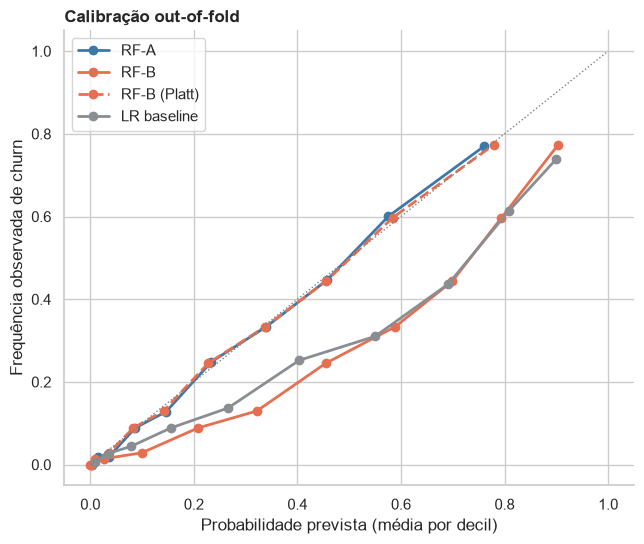

In [15]:
fig, ax = plt.subplots(figsize=(6.6, 5.6))
for n, c, ls in [("RF-A", C_A, "-"), ("RF-B", C_B, "-"), ("RF-B (Platt)", C_B, "--"), ("LR baseline", C_BASE, "-")]:
    q = pd.qcut(oof[n], 10, duplicates="drop")
    g = pd.DataFrame({"y": y_train_arr, "p": oof[n], "q": q}).groupby("q", observed=True).agg(y=("y", "mean"), p=("p", "mean"))
    ax.plot(g["p"], g["y"], marker="o", lw=2, color=c, ls=ls, label=n)
ax.plot([0, 1], [0, 1], ls=":", color="gray", lw=1)
ax.set_xlabel("Probabilidade prevista (média por decil)"); ax.set_ylabel("Frequência observada de churn")
ax.set_title("Calibração out-of-fold", loc="left", weight="bold"); ax.legend()
plt.tight_layout(); plt.show()

In [16]:
def thresholds_from_oof(p):
    pr, rc, th = precision_recall_curve(y_train_arr, p)
    f1 = 2 * pr * rc / (pr + rc + 1e-12)
    return th[int(np.nanargmax(f1[:-1]))], th[np.where(rc[:-1] >= RECALL_FLOOR)[0][-1]]

THR = {n: thresholds_from_oof(oof[n]) for n in ["RF-A", "RF-B", "LR baseline"]}
for n, (t1, t2) in THR.items():
    print(f"{n:12s} threshold F1 máx = {t1:.3f} | threshold recall ≥ {RECALL_FLOOR:.0%} = {t2:.3f}")

RF-A         threshold F1 máx = 0.325 | threshold recall ≥ 80% = 0.295
RF-B         threshold F1 máx = 0.545 | threshold recall ≥ 80% = 0.542
LR baseline  threshold F1 máx = 0.604 | threshold recall ≥ 80% = 0.464


### 7.1 Avaliação final no teste (uso único)

In [17]:
final_models = {n: FINAL[n]().fit(X_train, y_train) for n in ["RF-A", "RF-B", "LR baseline"]}
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}
proba_test["RF-B (Platt)"] = platt_apply(platt_B, proba_test["RF-B"])      # mapa ajustado só no treino (OOF)

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(y_test_arr), len(y_test_arr)) for _ in range(N_BOOT)]
boot = {n: np.array([[roc_auc_score(y_test_arr[i], proba_test[n][i]), average_precision_score(y_test_arr[i], proba_test[n][i]),
                      precision_at_recall(y_test_arr[i], proba_test[n][i])] for i in boot_idx]) for n in ["RF-A", "RF-B", "LR baseline"]}

rows = []
for n in ["LR baseline", "RF-A", "RF-B"]:
    s = score_all(y_test_arr, proba_test[n])
    ci = lambda k: np.percentile(boot[n][:, k], [2.5, 97.5])
    rows.append({"modelo": n, "AUC": f"{s['AUC']:.4f} [{ci(0)[0]:.3f}-{ci(0)[1]:.3f}]", "AP": f"{s['AP']:.4f} [{ci(1)[0]:.3f}-{ci(1)[1]:.3f}]",
                 P80: f"{s[P80]:.3f} [{ci(2)[0]:.3f}-{ci(2)[1]:.3f}]"})
display(pd.DataFrame(rows).style.hide(axis="index"))

rows = []
for a, b in [("RF-A", "LR baseline"), ("RF-B", "LR baseline"), ("RF-B", "RF-A")]:
    r = {"comparação": f"{a} − {b}"}
    for k, m in enumerate(["AUC", "AP", P80]):
        d = boot[a][:, k] - boot[b][:, k]
        lo, hi = np.percentile(d, [2.5, 97.5])
        r[f"Δ{m}"] = f"{d.mean():+.4f} [{lo:+.4f}; {hi:+.4f}]" + (" *" if (lo > 0 or hi < 0) else "")
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))
print("* = IC95 % (bootstrap pareado no teste) exclui zero.")
cal = {n: (brier_score_loss(y_test_arr, proba_test[n]), expected_calibration_error(y_test_arr, proba_test[n]))
       for n in ["LR baseline", "RF-A", "RF-B", "RF-B (Platt)"]}
print("Calibração no teste (Brier / ECE):", {n: (round(b, 4), round(e, 4)) for n, (b, e) in cal.items()})

modelo,AUC,AP,P@R80
LR baseline,0.8364 [0.814-0.858],0.6248 [0.572-0.678],0.496 [0.449-0.558]
RF-A,0.8565 [0.836-0.875],0.6705 [0.617-0.718],0.535 [0.481-0.584]
RF-B,0.8556 [0.835-0.874],0.6664 [0.614-0.714],0.542 [0.479-0.584]


comparação,ΔAUC,ΔAP,ΔP@R80
RF-A − LR baseline,+0.0200 [+0.0076; +0.0315] *,+0.0453 [+0.0107; +0.0789] *,+0.0351 [-0.0038; +0.0717]
RF-B − LR baseline,+0.0191 [+0.0062; +0.0308] *,+0.0412 [+0.0067; +0.0762] *,+0.0348 [-0.0036; +0.0727]
RF-B − RF-A,-0.0009 [-0.0030; +0.0012],-0.0041 [-0.0091; +0.0005],-0.0003 [-0.0190; +0.0154]


* = IC95 % (bootstrap pareado no teste) exclui zero.
Calibração no teste (Brier / ECE): {'LR baseline': (0.1651, 0.1266), 'RF-A': (0.132, 0.0142), 'RF-B': (0.1622, 0.1453), 'RF-B (Platt)': (0.1324, 0.0144)}


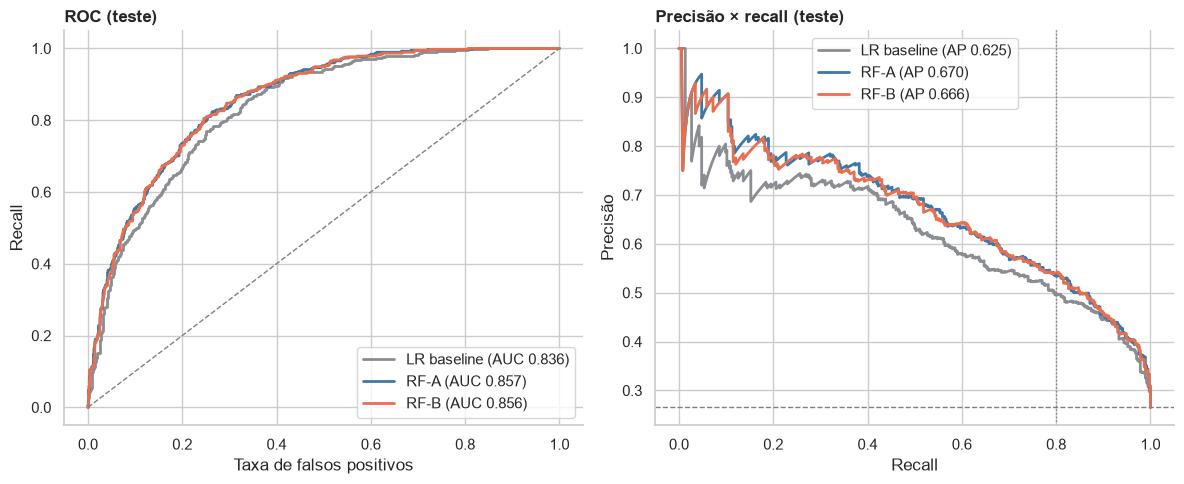

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for n, c in [("LR baseline", C_BASE), ("RF-A", C_A), ("RF-B", C_B)]:
    fpr, tpr, _ = roc_curve(y_test_arr, proba_test[n]); axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC {roc_auc_score(y_test_arr, proba_test[n]):.3f})")
    pr, rc, _ = precision_recall_curve(y_test_arr, proba_test[n]); axes[1].plot(rc, pr, color=c, lw=2, label=f"{n} (AP {average_precision_score(y_test_arr, proba_test[n]):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="gray", lw=1); axes[0].set_xlabel("Taxa de falsos positivos"); axes[0].set_ylabel("Recall"); axes[0].set_title("ROC (teste)", loc="left", weight="bold")
axes[1].axhline(y_test_arr.mean(), ls="--", color="gray", lw=1); axes[1].axvline(RECALL_FLOOR, ls=":", color="gray", lw=1)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precisão"); axes[1].set_title("Precisão × recall (teste)", loc="left", weight="bold")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

In [19]:
rows = []
for n in ["LR baseline", "RF-A", "RF-B"]:
    for label, thr in [("threshold 0,5", 0.5), ("F1 máximo (OOF)", THR[n][0]), (f"recall ≥ {RECALL_FLOOR:.0%} (OOF)", THR[n][1])]:
        pred = proba_test[n] >= thr
        tp = int((pred & (y_test_arr == 1)).sum()); fp = int((pred & (y_test_arr == 0)).sum()); fn = int((~pred & (y_test_arr == 1)).sum())
        rows.append({"modelo": n, "ponto de operação": label, "threshold": thr, "TP": tp, "FP": fp, "FN": fn,
                     "precisão": tp / (tp + fp), "recall": tp / (tp + fn), "F1": 2 * tp / (2 * tp + fp + fn)})
op_table = pd.DataFrame(rows)
display(op_table.style.format({"threshold": "{:.3f}", "precisão": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}"}).hide(axis="index"))

# Ganho em falsos positivos no MESMO recall (80 %), comparando as curvas precisão x recall no teste
n_pos_test = int(y_test_arr.sum()); tp80 = RECALL_FLOOR * n_pos_test
fp80 = {n: tp80 * (1 - precision_at_recall(y_test_arr, proba_test[n])) / precision_at_recall(y_test_arr, proba_test[n]) for n in ["LR baseline", "RF-A", "RF-B"]}
print(f"Falsos positivos esperados para capturar {RECALL_FLOOR:.0%} dos churners no teste (≈ {tp80:.0f} de {n_pos_test}): "
      + " | ".join(f"{n}: {v:.0f}" for n, v in fp80.items()))
print(f"FP evitados pelo RF-A sobre o baseline no mesmo recall: ≈ {fp80['LR baseline'] - fp80['RF-A']:.0f}")

modelo,ponto de operação,threshold,TP,FP,FN,precisão,recall,F1
LR baseline,"threshold 0,5",0.500,284,259,90,0.523,0.759,0.619
LR baseline,F1 máximo (OOF),0.604,251,208,123,0.547,0.671,0.603
LR baseline,recall ≥ 80% (OOF),0.464,294,288,80,0.505,0.786,0.615
RF-A,"threshold 0,5",0.500,204,101,170,0.669,0.545,0.601
RF-A,F1 máximo (OOF),0.325,289,240,85,0.546,0.773,0.640
RF-A,recall ≥ 80% (OOF),0.295,297,256,77,0.537,0.794,0.641
RF-B,"threshold 0,5",0.500,308,286,66,0.519,0.824,0.636
RF-B,F1 máximo (OOF),0.545,297,254,77,0.539,0.794,0.642
RF-B,recall ≥ 80% (OOF),0.542,301,254,73,0.542,0.805,0.648


Falsos positivos esperados para capturar 80% dos churners no teste (≈ 299 de 374): LR baseline: 304 | RF-A: 260 | RF-B: 253
FP evitados pelo RF-A sobre o baseline no mesmo recall: ≈ 44


**Leitura da avaliação final (teste, uso único):**

- **Ganho sobre o baseline é significativo no ranking:** RF-A − baseline, Δ AUC +0,0200 [+0,0076; +0,0315] e Δ AP +0,0453 [+0,0107; +0,0789]. RF-B idem (+0,0191 e +0,0412). RF-B − RF-A: empate.
- **O teste é mais difícil que a CV para todos** (baseline 0,848 → 0,836; RF-A 0,863 → 0,857), dentro dos intervalos. A ordem entre modelos se preserva.
- **Falsos positivos no mesmo recall:** com thresholds escolhidos no OOF, o baseline entrega recall 0,786 com 288 FP (precisão 0,505, F1 0,615); o RF-A, recall 0,794 com 256 FP (0,537; 0,641); o RF-B, recall 0,805 com 254 FP (0,542; 0,648). São ≈ 32 FP a menos **com recall maior**. Cuidado de leitura: o IC95 % do Δ `P@R80` no teste inclui zero (374 churners), então este é um ganho estimado, não demonstrado com a mesma confiança do ranking.
- **O corte 0,5 não serve para o RF-A:** sem peso de classe, ele dá recall 0,545 e precisão 0,669 (F1 0,601). É exatamente o problema mostrado na seção 2.1: o threshold deve vir do ponto de operação.
- **O que o baseline reproduzido confirma:** a linha "threshold 0,5" do baseline (TP 285, FP 259, FN 89, precisão 0,524, recall 0,762, F1 0,621) coincide com o resultado do `2-baseline.ipynb`, validando a comparação.

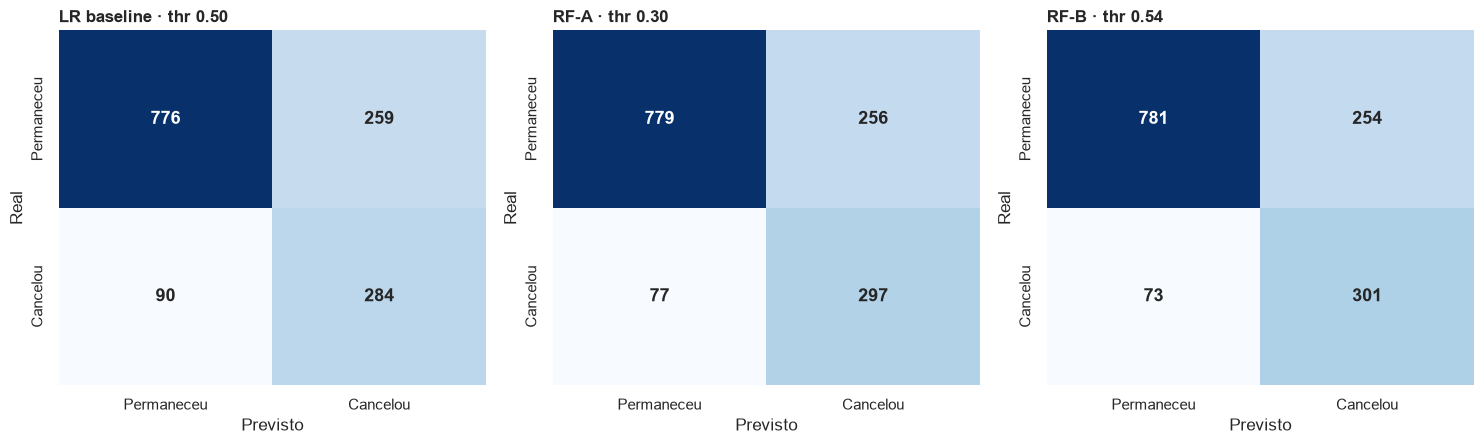

In [20]:
def lift_table(y_true, proba):
    d = pd.DataFrame({"y": y_true, "p": proba})
    d["decil"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    g = d.groupby("decil", observed=True).agg(clientes=("y", "size"), churners=("y", "sum"), churn=("y", "mean"))
    g["lift"] = g["churn"] / d["y"].mean(); g["recall acum."] = g["churners"].cumsum() / d["y"].sum()
    return g

lifts = pd.concat({n: lift_table(y_test_arr, proba_test[n])[["churn", "lift", "recall acum."]] for n in ["LR baseline", "RF-A", "RF-B"]}, axis=1)
display(lifts.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, n in zip(axes, ["LR baseline", "RF-A", "RF-B"]):
    thr = 0.5 if n == "LR baseline" else THR[n][1]
    cm = confusion_matrix(y_test_arr, (proba_test[n] >= thr).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 13, "weight": "bold"},
                xticklabels=["Permaneceu", "Cancelou"], yticklabels=["Permaneceu", "Cancelou"])
    ax.set_title(f"{n} · thr {thr:.2f}", loc="left", weight="bold"); ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

**Leitura do lift:** o 1º decil de risco tem 77 % de churn no RF-A e no RF-B (lift 2,9), contra 74 % (2,8) no baseline. Os 4 primeiros decis capturam 81 % dos churners (baseline: 78 %), e os 4 últimos (40 % da base) contêm só ≈ 5,6 % deles (baseline: 6,7 %). O modelo serve bem para **concentrar a ação** nos clientes de maior risco e **poupar** uma grande parte da base.

## 8. Interpretação do Random Forest

O RF não é intrinsecamente interpretável, então a leitura é **pós-hoc**: importância por permutação (no teste, queda de AP) e efeito médio "e se este cliente tivesse X?". Os cuidados de leitura (colinearidade preço × serviços; associação, não causa) estão ao final desta seção.

Correlação de postos entre as importâncias de RF-A e RF-B: 0.96


,RF-A,RF-B,média
Contract,0.0857,0.1243,0.1050
Tenure Months,0.0695,0.0721,0.0708
Dependents,0.0474,0.0557,0.0516
Internet Service,0.0374,0.0543,0.0459
Total Charges,0.0358,0.0434,0.0396
Online Security,0.0184,0.0128,0.0156
Tech Support,0.0130,0.0083,0.0106
Monthly Charges,0.0067,0.0080,0.0073
Partner,0.0029,0.0028,0.0029
Payment Method,0.0009,0.0025,0.0017


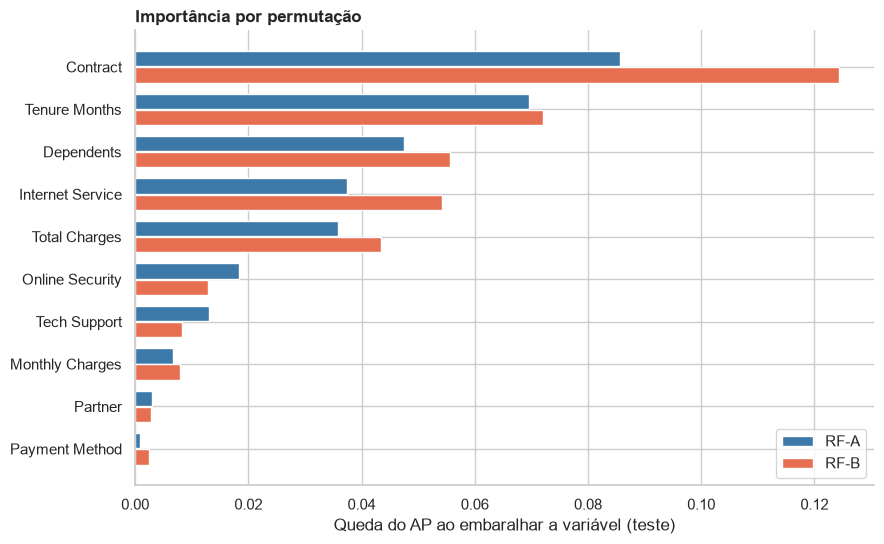

In [21]:
perm = {}
for n in ["RF-A", "RF-B"]:
    r = permutation_importance(final_models[n], X_test, y_test, scoring="average_precision", n_repeats=5, random_state=SEED)
    perm[n] = pd.Series(r.importances_mean, index=X_test.columns)
imp = pd.DataFrame(perm).loc[FEATURES]
imp["média"] = imp.mean(axis=1)
imp = imp.sort_values("média", ascending=False)
rho_imp = spearmanr(imp["RF-A"], imp["RF-B"]).statistic
print(f"Correlação de postos entre as importâncias de RF-A e RF-B: {rho_imp:.2f}")
display(imp.head(10).style.format("{:.4f}"))

fig, ax = plt.subplots(figsize=(9, 5.6))
top = imp.head(10).iloc[::-1]; ypos = np.arange(len(top))
ax.barh(ypos + 0.19, top["RF-A"], height=0.36, color=C_A, label="RF-A")
ax.barh(ypos - 0.19, top["RF-B"], height=0.36, color=C_B, label="RF-B")
ax.set_yticks(ypos); ax.set_yticklabels(top.index); ax.set_xlabel("Queda do AP ao embaralhar a variável (teste)")
ax.set_title("Importância por permutação", loc="left", weight="bold"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura:** `Contract` (0,086 e 0,124 de queda de AP), `Tenure Months` (0,069 e 0,072), `Dependents` (0,047 e 0,056), `Internet Service` (0,037 e 0,054) e `Total Charges` (0,036 e 0,043) dominam nas duas versões (correlação de postos 0,96). `Monthly Charges` pesa pouco (0,007), pois o RF usa `Total Charges`, que carrega praticamente a mesma informação (≈ tenure × mensalidade): efeito da colinearidade, não de irrelevância do preço.

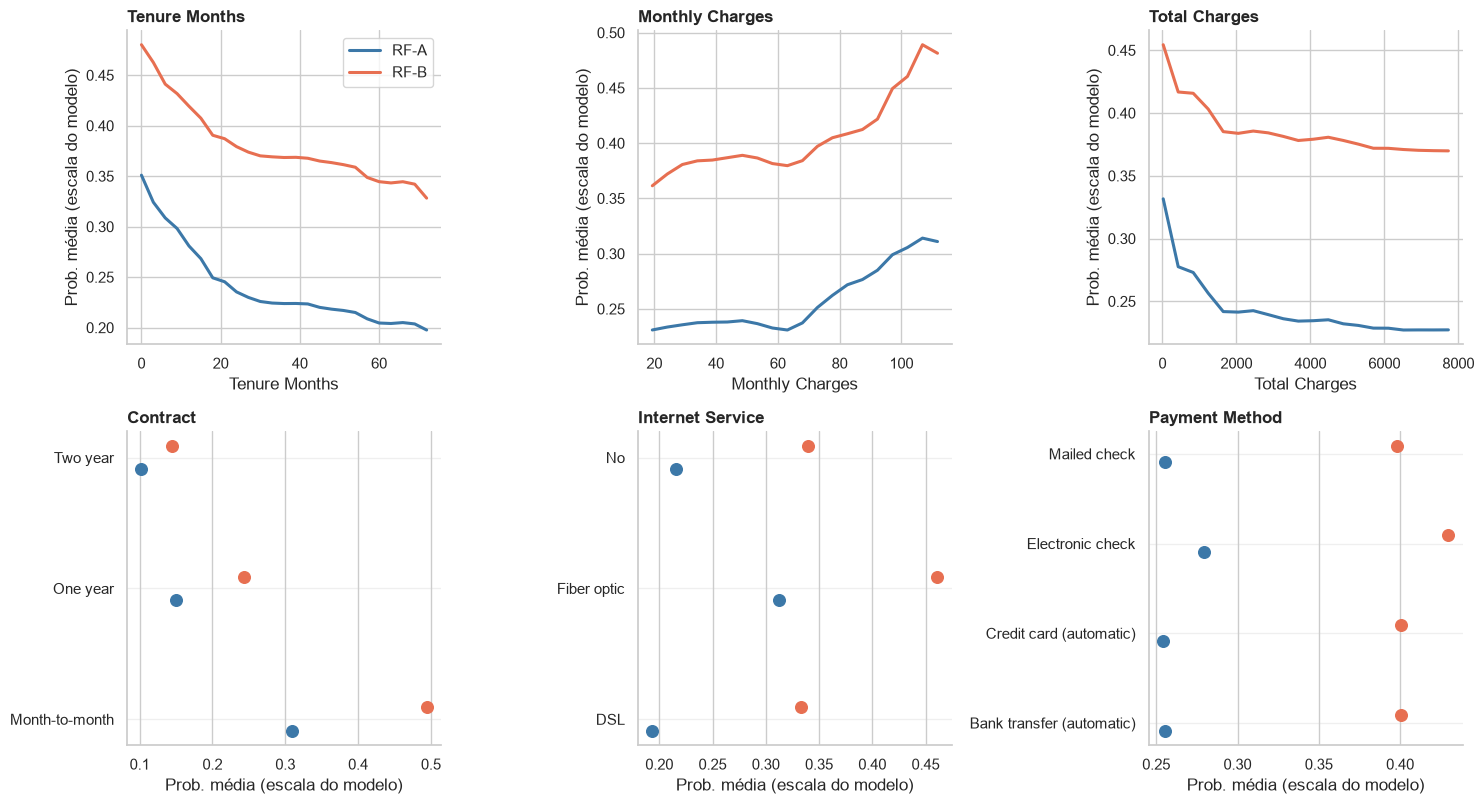

In [22]:
def what_if(model, col, values, ref=X_train):
    out = []
    for v in values:
        Xv = ref.copy(); Xv[col] = v
        out.append(model.predict_proba(Xv)[:, 1].mean())
    return np.array(out)

num_grids = {"Tenure Months": np.arange(0, 73, 3),
             "Monthly Charges": np.linspace(*np.percentile(X_train["Monthly Charges"], [2, 98]), 20),
             "Total Charges": np.linspace(*np.percentile(X_train["Total Charges"].dropna(), [2, 98]), 20)}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, (col, grid) in zip(axes[0], num_grids.items()):
    for n, c in [("RF-A", C_A), ("RF-B", C_B)]:
        ax.plot(grid, what_if(final_models[n], col, grid), color=c, lw=2.2, label=n)
    ax.set_xlabel(col); ax.set_ylabel("Prob. média (escala do modelo)"); ax.set_title(col, loc="left", weight="bold")
axes[0][0].legend()
for ax, col in zip(axes[1], ["Contract", "Internet Service", "Payment Method"]):
    levels = sorted(X_train[col].unique())
    for k, (n, c) in enumerate([("RF-A", C_A), ("RF-B", C_B)]):
        vals = [what_if(final_models[n], col, [lv])[0] for lv in levels]
        ax.scatter(vals, np.arange(len(levels)) + (k - 0.5) * 0.18, color=c, s=70, label=n, zorder=3)
    ax.set_yticks(range(len(levels))); ax.set_yticklabels(levels); ax.set_xlabel("Prob. média (escala do modelo)")
    ax.set_title(col, loc="left", weight="bold"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Cuidados de leitura:** (1) o preço mensal é quase uma função linear dos serviços (R² = 0,9988, seção 9.5), então o efeito *isolado* de `Monthly Charges` e `Total Charges` não é identificável pelos dados e as curvas podem diferir entre modelos sem que isso afete o ranking; (2) o "e se" altera uma variável por vez e cria combinações que não existem na base; (3) o RF-B usa `class_weight`, então sua escala de probabilidade é deslocada (as curvas comparam *formas*, não níveis); (4) tudo isso é associação, não causa: serve para entender o modelo, não para prescrever ações.

### 8.1 Desempenho por segmento (out-of-fold, RF-A)

A EDA mostra churn concentrado em poucos segmentos. Um bom AUC global pode esconder fraqueza justamente neles.

In [23]:
seg = X_train[FEATURES].copy()
seg["y"] = y_train_arr; seg["p"] = oof["RF-A"]
seg["Faixa de tenure"] = pd.cut(seg["Tenure Months"], [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
rows = []
for col in ["Contract", "Faixa de tenure", "Internet Service", "Payment Method"]:
    for lv, g in seg.groupby(col, observed=True):
        if g["y"].nunique() < 2:
            continue
        rows.append({"variável": col, "grupo": str(lv), "n": len(g), "churn real": g["y"].mean(), "prev. média": g["p"].mean(),
                     "AUC": roc_auc_score(g["y"], g["p"]), "AP": average_precision_score(g["y"], g["p"])})
seg_table = pd.DataFrame(rows)
display(seg_table.style.format({c: "{:.3f}" for c in ["churn real", "prev. média", "AUC", "AP"]}).hide(axis="index"))

variável,grupo,n,churn real,prev. média,AUC,AP
Contract,Month-to-month,3102,0.427,0.425,0.775,0.715
Contract,One year,1173,0.111,0.111,0.788,0.247
Contract,Two year,1359,0.029,0.034,0.820,0.152
Faixa de tenure,0-6,1170,0.522,0.513,0.784,0.791
Faixa de tenure,7-12,567,0.372,0.372,0.821,0.726
Faixa de tenure,13-24,818,0.286,0.282,0.818,0.580
Faixa de tenure,25-48,1290,0.202,0.206,0.835,0.524
Faixa de tenure,49-72,1789,0.099,0.105,0.852,0.378
Internet Service,DSL,1937,0.187,0.191,0.821,0.487
Internet Service,Fiber optic,2483,0.421,0.416,0.818,0.749


**Leitura por segmento:**

- **Calibração boa:** a probabilidade média prevista fica a ≤ 0,02 do churn real em todos os grupos (maior desvio: cheque eletrônico, 0,437 previsto contra 0,457 real).
- **O ranking é mais fraco onde há mais churn:** contrato mensal (churn 43 %, AUC 0,775), 0 a 6 meses (52 %, 0,784) e cheque eletrônico (46 %, 0,793). O contrato anual (11 %) também tem AUC baixo (0,788). Nos segmentos estáveis o AUC vai de 0,82 a 0,87. O AUC global (0,863) é sustentado pela separação *entre* segmentos (quase ninguém cancela contrato de dois anos); *dentro* dos perfis de risco, separar quem sai de quem fica é bem mais difícil.

## 9. Evidências sobre o teto de desempenho

Cada subseção ataca uma explicação alternativa para o AUC ≈ 0,86 do RF: falta de capacidade, falta de dados, falta de features, falta de diversidade de modelos, estrutura escondida em preço ou renovação, ruído de rótulo.

### 9.1 Capacidade do modelo: curva de validação em `min_samples_leaf`

Árvores totalmente crescidas (`max_depth=None`) com folha mínima crescente. Se o problema fosse falta de capacidade, o AUC de validação subiria com árvores mais profundas; se for ruído/sobreposição, ele sobe com **regularização** e depois estabiliza.

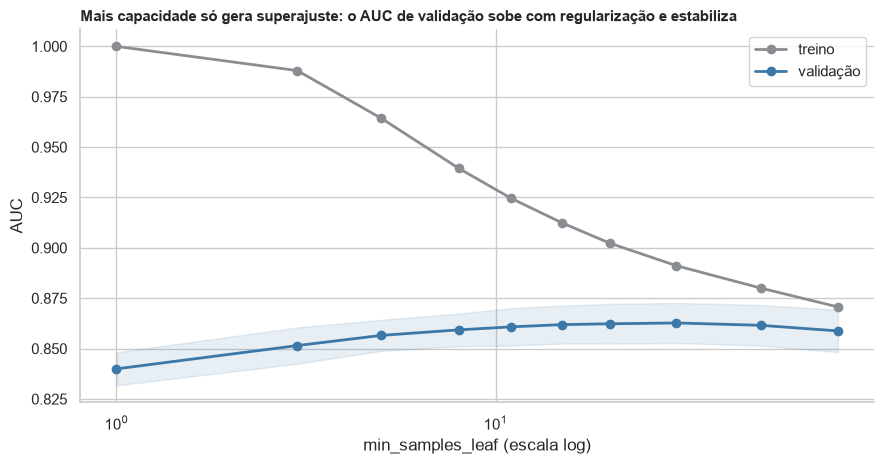

min_samples_leaf,AUC treino,AUC validação,dp validação,AP validação
1,0.9999,0.8400,0.0082,0.6383
3,0.9880,0.8515,0.0090,0.6625
5,0.9642,0.8566,0.0077,0.6735
8,0.9394,0.8593,0.0081,0.6787
11,0.9245,0.8608,0.0093,0.6828
15,0.9123,0.8619,0.0094,0.6842
20,0.9023,0.8623,0.0099,0.6837
30,0.8911,0.8627,0.0099,0.6845
50,0.8801,0.8616,0.0101,0.6834
80,0.8707,0.8588,0.0105,0.6814


Melhor AUC de validação: 0.8627 com folha 30. Platô (a ≤ 0,002 do máximo): folhas [11, 15, 20, 30, 50]. Com folha 1 (padrão): 0.8400 (treino 1.000).


In [24]:
leaf_grid = [1, 3, 5, 8, 11, 15, 20, 30, 50, 80]
rows = []
for leaf in leaf_grid:
    tr, va, vap = [], [], []
    for a, b in CV5.split(X_train, y_train):
        m = make_rf(n_estimators=150, max_depth=None, min_samples_split=2, ccp_alpha=0.0, min_samples_leaf=leaf).fit(X_train.iloc[a], y_train.iloc[a])
        tr.append(roc_auc_score(y_train_arr[a], m.predict_proba(X_train.iloc[a])[:, 1]))
        pb = m.predict_proba(X_train.iloc[b])[:, 1]
        va.append(roc_auc_score(y_train_arr[b], pb)); vap.append(average_precision_score(y_train_arr[b], pb))
    rows.append({"min_samples_leaf": leaf, "AUC treino": np.mean(tr), "AUC validação": np.mean(va), "dp validação": np.std(va), "AP validação": np.mean(vap)})
vc = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(vc["min_samples_leaf"], vc["AUC treino"], marker="o", color=C_BASE, lw=2, label="treino")
ax.plot(vc["min_samples_leaf"], vc["AUC validação"], marker="o", color=C_A, lw=2, label="validação")
ax.fill_between(vc["min_samples_leaf"], vc["AUC validação"] - vc["dp validação"], vc["AUC validação"] + vc["dp validação"], color=C_A, alpha=0.12)
ax.set_xscale("log"); ax.set_xlabel("min_samples_leaf (escala log)"); ax.set_ylabel("AUC")
ax.set_title("Mais capacidade só gera superajuste: o AUC de validação sobe com regularização e estabiliza", loc="left", weight="bold", fontsize=11)
ax.legend(); plt.tight_layout(); plt.show()
display(vc.style.format({c: "{:.4f}" for c in vc.columns if c != "min_samples_leaf"}).hide(axis="index"))
best_leaf = vc.loc[vc["AUC validação"].idxmax()]
plateau = vc[vc["AUC validação"] >= best_leaf["AUC validação"] - 0.002]["min_samples_leaf"].tolist()
print(f"Melhor AUC de validação: {best_leaf['AUC validação']:.4f} com folha {int(best_leaf['min_samples_leaf'])}. "
      f"Platô (a ≤ 0,002 do máximo): folhas {plateau}. Com folha 1 (padrão): {vc.loc[0, 'AUC validação']:.4f} (treino {vc.loc[0, 'AUC treino']:.3f}).")

**Leitura:** capacidade **não** é o limite. Com folha de 1 amostra (o padrão), o AUC de treino é 1,000 e o de validação 0,840: o modelo decora o treino. Regularizar sobe a validação até **0,8627 (folha 30)**, com platô entre folhas de 11 a 50, e a diferença treino-validação cai de 0,160 para 0,028. Mais regularização (folha 80) já piora. Ou seja, o ganho do RF vem de *cortar variância*, e acima do platô não há mais nada a extrair: o RF-A (folha 11) e o RF-B (folha 21) estão dentro dele.

### 9.2 Volume de dados: curva de aprendizado

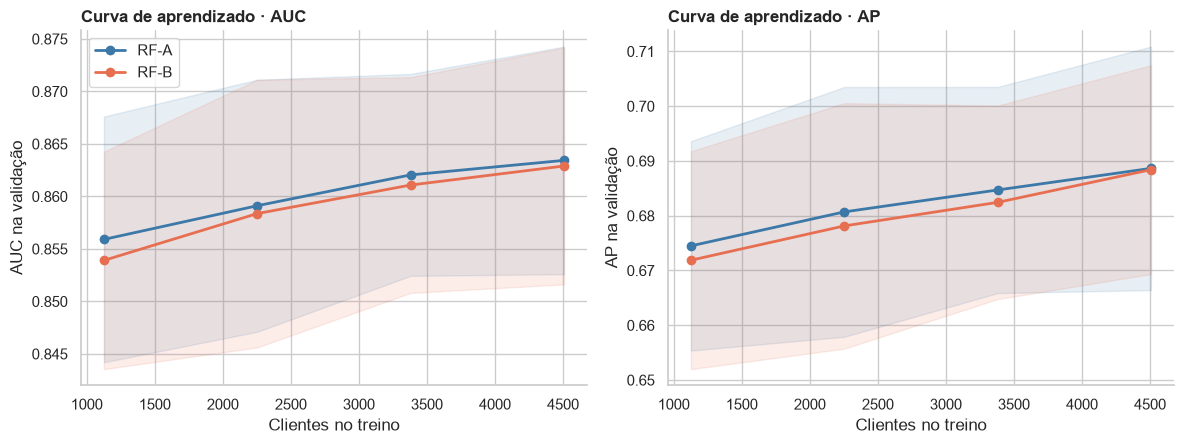

RF-A: AUC com 50 % dos dados 0.8591 | 75 % 0.8620 | 100 % 0.8634 | ganho de 75 % → 100 %: +0.0014
RF-B: AUC com 50 % dos dados 0.8584 | 75 % 0.8611 | 100 % 0.8629 | ganho de 75 % → 100 %: +0.0018


In [25]:
def learning_curve_cv(factory, fractions=(0.25, 0.5, 0.75, 1.0), seed=0):
    rng_l = np.random.default_rng(seed); rows = []
    for fold, (a, b) in enumerate(CV5.split(X_train, y_train)):
        for f in fractions:
            idx = rng_l.choice(a, int(len(a) * f), replace=False)
            p = factory().fit(X_train.iloc[idx], y_train.iloc[idx]).predict_proba(X_train.iloc[b])[:, 1]
            rows.append({"fração": f, "n": len(idx), "fold": fold, "AUC": roc_auc_score(y_train_arr[b], p), "AP": average_precision_score(y_train_arr[b], p)})
    return pd.DataFrame(rows)

lc = {n: learning_curve_cv(lambda p=pp: make_rf(**{**p, "n_estimators": 200})) for n, pp in [("RF-A", PARAMS_A), ("RF-B", PARAMS_B)]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, metric in zip(axes, ["AUC", "AP"]):
    for n, c in [("RF-A", C_A), ("RF-B", C_B)]:
        g = lc[n].groupby("fração").agg(n=("n", "mean"), m=(metric, "mean"), sd=(metric, "std"))
        ax.plot(g["n"], g["m"], marker="o", color=c, lw=2, label=n); ax.fill_between(g["n"], g["m"] - g["sd"], g["m"] + g["sd"], color=c, alpha=0.12)
    ax.set_xlabel("Clientes no treino"); ax.set_ylabel(f"{metric} na validação"); ax.set_title(f"Curva de aprendizado · {metric}", loc="left", weight="bold")
axes[0].legend(); plt.tight_layout(); plt.show()
lc_table = pd.concat({n: lc[n].groupby("fração").agg(clientes=("n", "mean"), AUC=("AUC", "mean"), AP=("AP", "mean")) for n in lc}, axis=1)
display(lc_table.style.format({c: "{:.0f}" if c[1] == "clientes" else "{:.4f}" for c in lc_table.columns}))
for n in lc:
    g = lc[n].groupby("fração")["AUC"].mean()
    print(f"{n}: AUC com 50 % dos dados {g[0.5]:.4f} | 75 % {g[0.75]:.4f} | 100 % {g[1.0]:.4f} | ganho de 75 % → 100 %: {g[1.0] - g[0.75]:+.4f}")

**Leitura:** o AUC ainda sobe com mais dados, mas com **retornos decrescentes**: cada acréscimo de ≈ 1.100 clientes rendeu +0,003, +0,003 e +0,001 no RF-A, e de 75 % para 100 % o ganho é +0,0014 (RF-A) e +0,0018 (RF-B), perto de 1/6 do desvio entre folds (≈ 0,009). Se a tendência se mantiver (extrapolação, **não medida**), dobrar a base renderia algo da ordem de +0,002 a +0,004 de AUC, insuficiente para mudar o ponto de operação. O RF, por ter mais variância que modelos aditivos, ainda aproveita um pouco mais de dados do que eles, mas não o bastante para ser a alavanca.

### 9.3 Variáveis: curva de acréscimo (RF-A)

Variáveis ordenadas por informação mútua com o alvo **no treino** (sem olhar o teste) e adicionadas uma a uma ao RF-A.

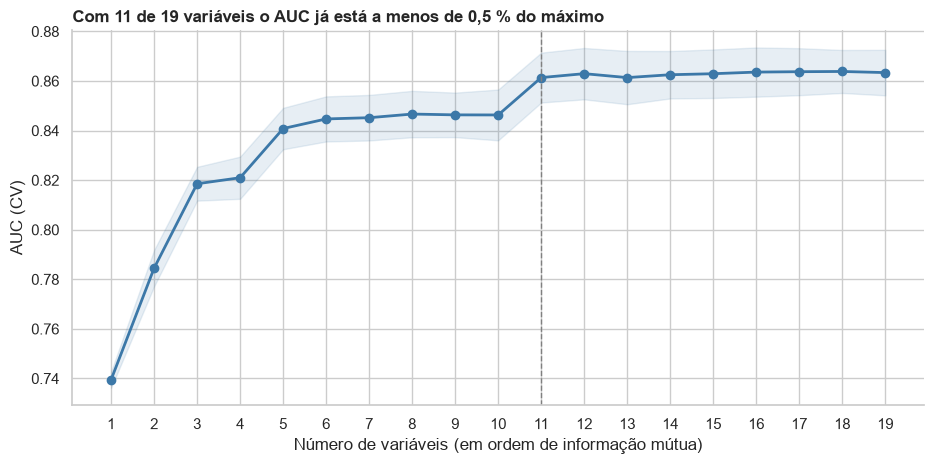

k,variável adicionada,AUC (CV),dp
1,Contract,0.7395,0.0032
2,Tenure Months,0.7845,0.0073
3,Online Security,0.8185,0.0068
4,Tech Support,0.8210,0.0085
5,Internet Service,0.8408,0.0084
6,Monthly Charges,0.8447,0.0091
7,Online Backup,0.8452,0.0092
8,Payment Method,0.8467,0.0094
9,Device Protection,0.8463,0.0090
10,Total Charges,0.8463,0.0102


AUC com 1 variável: 0.7395 | com 2: 0.7845 | com 5: 0.8408 | com 11: 0.8614 | com todas (19): 0.8634
As 8 últimas variáveis somam +0.0020 de AUC (desvio entre folds ≈ 0.009).


In [26]:
Xo = X_train[FEATURES].copy()
for c in CAT:
    Xo[c] = Xo[c].astype("category").cat.codes
Xo["Total Charges"] = Xo["Total Charges"].fillna(0)
mi = pd.Series(mutual_info_classif(Xo, y_train, discrete_features=[c in CAT for c in FEATURES], random_state=SEED), index=FEATURES)
order = mi.sort_values(ascending=False).index.tolist()

rows = []
for k in range(1, len(order) + 1):
    cols = order[:k]; aucs = []
    for a, b in CV5.split(X_train, y_train):
        m = make_rf(cat=[c for c in cols if c in CAT], num=[c for c in cols if c in NUM], **{**PARAMS_A, "n_estimators": 100}).fit(X_train.iloc[a], y_train.iloc[a])
        aucs.append(roc_auc_score(y_train_arr[b], m.predict_proba(X_train.iloc[b])[:, 1]))
    rows.append({"k": k, "variável adicionada": order[k - 1], "AUC (CV)": np.mean(aucs), "dp": np.std(aucs)})
accrual = pd.DataFrame(rows)
full_auc = accrual["AUC (CV)"].iloc[-1]
k_plateau = int(accrual.loc[accrual["AUC (CV)"] >= 0.995 * full_auc, "k"].iloc[0])
auc_k = accrual.set_index("k")["AUC (CV)"]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(accrual["k"], accrual["AUC (CV)"], marker="o", color=C_A, lw=2)
ax.fill_between(accrual["k"], accrual["AUC (CV)"] - accrual["dp"], accrual["AUC (CV)"] + accrual["dp"], color=C_A, alpha=0.12)
ax.axvline(k_plateau, color="gray", ls="--", lw=1); ax.set_xticks(accrual["k"])
ax.set_xlabel("Número de variáveis (em ordem de informação mútua)"); ax.set_ylabel("AUC (CV)")
ax.set_title(f"Com {k_plateau} de {len(order)} variáveis o AUC já está a menos de 0,5 % do máximo", loc="left", weight="bold")
plt.tight_layout(); plt.show()
display(accrual.style.format({"AUC (CV)": "{:.4f}", "dp": "{:.4f}"}).hide(axis="index"))
print(f"AUC com 1 variável: {auc_k[1]:.4f} | com 2: {auc_k[2]:.4f} | com 5: {auc_k[5]:.4f} | com {k_plateau}: {auc_k[k_plateau]:.4f} | com todas ({len(order)}): {full_auc:.4f}")
print(f"As {len(order) - k_plateau} últimas variáveis somam {full_auc - auc_k[k_plateau]:+.4f} de AUC (desvio entre folds ≈ {accrual['dp'].iloc[-1]:.3f}).")

**Leitura:** o sinal está concentrado. Só `Contract` dá AUC 0,739; com `Tenure Months`, 0,784; com 5 variáveis, 0,841. A 11ª variável (`Dependents`) provoca um salto de +0,015 (para 0,861): ela entra tarde na ordenação por informação mútua (baixa associação marginal), mas tem forte efeito *condicional* (3ª em importância na seção 8). Depois disso, **as 8 últimas variáveis somam +0,002 de AUC**, cerca de 4 vezes abaixo do desvio entre folds (≈ 0,009). A cauda de variáveis não acrescenta nada distinguível de ruído ao ranking.

### 9.4 Diversidade de modelos: o RF tem concorrente que enxergue algo a mais?

Se houvesse sinal que o RF não captura, uma família diferente (boosting aditivo, regressão com splines, árvores extremamente aleatórias) ou um ensemble revelaria. Mesmos folds das hipóteses (CV 5 × 2).

In [27]:
def make_et():
    pre = ColumnTransformer([("num", SimpleImputer(strategy="constant", fill_value=0.0), NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return Pipeline([("pre", pre), ("clf", ExtraTreesClassifier(n_estimators=400, criterion="entropy", min_samples_leaf=8, max_features=0.5, random_state=SEED))])


def make_hgb_additive():
    pre = ColumnTransformer([("num", "passthrough", NUM), ("cat", OrdinalEncoder(), CAT)])
    clf = HistGradientBoostingClassifier(max_depth=1, max_iter=800, learning_rate=0.05, l2_regularization=5.0, min_samples_leaf=40,
                                         categorical_features=list(range(len(NUM), len(NUM) + len(CAT))), random_state=SEED)
    return Pipeline([("pre", pre), ("clf", clf)])

fam_new = run_cv({"ExtraTrees": make_et, "GBM aditivo": make_hgb_additive, "LR com splines": make_lr_spline}, CV_H)
fam_old = cand_folds[(cand_folds["modelo"].isin([NAME_A, NAME_B, LR_BASE])) & (cand_folds["fold"] < 10)].copy()
fam_old["modelo"] = fam_old["modelo"].replace({NAME_A: "RF-A", NAME_B: "RF-B"})
fam = pd.concat([fam_new, fam_old], ignore_index=True)
fam_means = fam.groupby("modelo")[["AUC", "AP", P80]].mean().sort_values("AP", ascending=False)
display(fam_means.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}"}))
rows = []
for other in ["RF-B", "ExtraTrees", "GBM aditivo", "LR com splines"]:
    r = {"A − B": f"{other} − RF-A"}
    for m in ["AUC", "AP", P80]:
        d, se, _ = paired(fam, other, "RF-A", m); r[f"Δ{m} (EP)"] = f"{d:+.4f} ({se:.4f})"
    rows.append(r)
display(pd.DataFrame(rows).style.hide(axis="index"))

,AUC,AP,P@R80
modelo,,,
GBM aditivo,0.8637,0.6924,0.545
LR com splines,0.8622,0.6898,0.547
RF-A,0.8633,0.6894,0.546
RF-B,0.8626,0.6893,0.548
ExtraTrees,0.8531,0.6607,0.528
"LR baseline (usuário, com geo)",0.8476,0.6534,0.521


A − B,ΔAUC (EP),ΔAP (EP),ΔP@R80 (EP)
RF-B − RF-A,-0.0007 (0.0004),-0.0002 (0.0008),+0.0016 (0.0026)
ExtraTrees − RF-A,-0.0102 (0.0012),-0.0287 (0.0044),-0.0182 (0.0055)
GBM aditivo − RF-A,+0.0004 (0.0014),+0.0030 (0.0029),-0.0007 (0.0040)
LR com splines − RF-A,-0.0011 (0.0015),+0.0003 (0.0025),+0.0013 (0.0045)


**Leitura:** GBM aditivo (Δ AUC +0,0004, EP 0,0014) e regressão com splines (−0,0011, EP 0,0015) **empatam** com o RF-A; RF-B também (−0,0007). O ExtraTrees é claramente pior (−0,0102, EP 0,0012), e o baseline de LR, pior ainda (0,848). Famílias de modelos com vieses indutivos muito diferentes chegam a AUC 0,862-0,864: o RF não está deixando de capturar algo que os demais capturam.

In [28]:
def rank_avg(ps):
    return np.mean([rankdata(p) / len(p) for p in ps], axis=0)

oof["LR com splines"] = cross_val_predict(make_lr_spline(), X_train, y_train, cv=CV5, method="predict_proba")[:, 1]
oof["GBM aditivo"] = cross_val_predict(make_hgb_additive(), X_train, y_train, cv=CV5, method="predict_proba")[:, 1]
blends = {"RF-A (isolado)": oof["RF-A"],
          "GBM aditivo (isolado)": oof["GBM aditivo"],
          "LR com splines (isolado)": oof["LR com splines"],
          "RF-A + RF-B": rank_avg([oof["RF-A"], oof["RF-B"]]),
          "RF-A + RF-B + GBM aditivo + LR com splines": rank_avg([oof["RF-A"], oof["RF-B"], oof["GBM aditivo"], oof["LR com splines"]])}
ens_table = pd.DataFrame({n: {k: v for k, v in score_all(y_train_arr, p).items() if k in ("AUC", "AP", P80)} for n, p in blends.items()}).T
display(ens_table.style.format({"AUC": "{:.4f}", "AP": "{:.4f}", P80: "{:.3f}"}))
fp100 = lambda p: 100 * (1 - p) / p
best_iso = ens_table.loc[["RF-A (isolado)", "GBM aditivo (isolado)", "LR com splines (isolado)"], "AUC"].idxmax()
e4 = ens_table.iloc[-1]
print(f"Ensemble de 4 modelos contra o RF-A: ΔAUC = {e4['AUC'] - ens_table.loc['RF-A (isolado)', 'AUC']:+.4f} | contra o melhor isolado ({best_iso}): ΔAUC = {e4['AUC'] - ens_table.loc[best_iso, 'AUC']:+.4f}")
print(f"Precisão@recall 80 %: RF-A {ens_table.loc['RF-A (isolado)', P80]:.3f} -> ensemble {e4[P80]:.3f} "
      f"({fp100(ens_table.loc['RF-A (isolado)', P80]):.0f} -> {fp100(e4[P80]):.0f} FP por 100 churners captados)")

,AUC,AP,P@R80
RF-A (isolado),0.8626,0.6839,0.542
GBM aditivo (isolado),0.8629,0.6901,0.546
LR com splines (isolado),0.8617,0.6881,0.546
RF-A + RF-B,0.8626,0.6847,0.548
RF-A + RF-B + GBM aditivo + LR com splines,0.8651,0.6907,0.548


Ensemble de 4 modelos contra o RF-A: ΔAUC = +0.0025 | contra o melhor isolado (GBM aditivo (isolado)): ΔAUC = +0.0022
Precisão@recall 80 %: RF-A 0.542 -> ensemble 0.548 (84 -> 82 FP por 100 churners captados)


**Leitura:** o ensemble de 4 modelos soma +0,0025 de AUC sobre o RF-A e +0,0022 sobre o melhor modelo isolado (o GBM aditivo, 0,8629); a precisão@recall 80 % vai de 0,542 para 0,548 (84 → 82 falsos positivos por 100 churners captados). Se houvesse informação complementar que nenhum modelo isolado captura, o ensemble a revelaria. O ganho equivale a cerca de 1/4 do desvio entre folds (≈ 0,009) e não muda o ponto de operação de forma relevante.

### 9.5 Estrutura escondida: preço relativo e ciclo de renovação (hipóteses da EDA)

In [29]:
services = ["Phone Service", "Multiple Lines", "Internet Service", "Online Security", "Online Backup",
            "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies"]
S = pd.get_dummies(X_train[services])
price_model = LinearRegression().fit(S, X_train["Monthly Charges"])
resid = X_train["Monthly Charges"] - price_model.predict(S)
print(f"(a) R² do preço mensal explicado só pelos serviços contratados: {price_model.score(S, X_train['Monthly Charges']):.4f} | desvio do resíduo: R$ {resid.std():.2f}")
q = pd.qcut(resid, 5)
display(pd.DataFrame({"churn": y_train.groupby(q, observed=True).mean(), "n": y_train.groupby(q, observed=True).size()})
        .rename_axis("quintil do resíduo de preço").style.format({"churn": "{:.3f}"}))
one_year = X_train["Contract"] == "One year"
cycle = pd.crosstab(X_train.loc[one_year, "Tenure Months"] % 12, y_train[one_year])
chi2, p_cycle, _, _ = chi2_contingency(cycle)
rate = y_train[one_year].groupby(X_train.loc[one_year, "Tenure Months"] % 12).mean()
print(f"(b) Contrato de 1 ano: churn por mês do ciclo (tenure mod 12) varia de {rate.min():.3f} a {rate.max():.3f}; "
      f"χ² de homogeneidade p = {p_cycle:.2f}  ->  {'sem evidência de ciclo' if p_cycle > 0.05 else 'há evidência de ciclo'}")

(a) R² do preço mensal explicado só pelos serviços contratados: 0.9988 | desvio do resíduo: R$ 1.03


,churn,n
quintil do resíduo de preço,,
"(-4.243, -0.764]",0.289,1136
"(-0.764, -0.231]",0.271,1118
"(-0.231, 0.214]",0.250,1126
"(0.214, 0.771]",0.249,1127
"(0.771, 4.808]",0.267,1127


(b) Contrato de 1 ano: churn por mês do ciclo (tenure mod 12) varia de 0.053 a 0.152; χ² de homogeneidade p = 0.18  ->  sem evidência de ciclo


**Leitura:** as duas hipóteses clássicas de feature engineering para churn de telecom **não têm sinal aqui**:

- O preço mensal é explicado quase integralmente pelos serviços (R² = 0,9988, desvio do resíduo ≈ R$ 1). Não existe "desconto" ou "sobrepreço" informativo, e o churn por quintil do resíduo não é monotônico (0,289 → 0,271 → 0,250 → 0,249 → 0,267). Sugere uma estrutura de preços simples, típica de dado de demonstração.
- O churn de contratos anuais **não concentra** em marcos de renovação (χ² de homogeneidade, p = 0,18).

### 9.6 Contraste: a variável que quebraria o teto

Só como **diagnóstico** (a EDA, seção 15, já a trata com ressalva; não é feature e não deve ser usada).

In [30]:
cs = raw.loc[X_train.index, "Churn Score"]
print(f"AUC do Churn Score sozinho (treino): {roc_auc_score(y_train_arr, cs):.3f}  vs  AUC OOF do RF-A: {roc_auc_score(y_train_arr, oof['RF-A']):.3f}")
print(f"Faixa do Churn Score entre churners: {cs[y_train_arr == 1].min()}-{cs[y_train_arr == 1].max()} | entre não-churners: {cs[y_train_arr == 0].min()}-{cs[y_train_arr == 0].max()}")
print("Uma variável única supera todo o modelo e separa quase por corte simples: padrão compatível com uma variável construída com o desfecho.")

AUC do Churn Score sozinho (treino): 0.941  vs  AUC OOF do RF-A: 0.863
Faixa do Churn Score entre churners: 65-100 | entre não-churners: 5-80
Uma variável única supera todo o modelo e separa quase por corte simples: padrão compatível com uma variável construída com o desfecho.


**Leitura:** existe uma variável que quebra o teto (AUC 0,941 sozinha, contra 0,863 do RF-A), mas ela separa os grupos quase por corte simples (todos os churners ≥ 65, não-churners ≤ 80). É o padrão de uma variável construída *com* o desfecho, como a EDA já sugere ao tratá-la com ressalva. O que ela mostra é que **o sinal que falta não está nas variáveis legítimas**.

## 10. Conclusão: por que o desempenho é este e por que não dá para otimizar mais com estes dados

### O que as melhores versões entregam

Sobre o baseline do usuário, no teste: AUC 0,8364 → 0,8565 e AP 0,6247 → 0,6705 (ambos com IC95 % do ganho excluindo zero), probabilidades calibradas (ECE 0,127 → 0,014), 1º decil com 77 % de churn (lift 2,9) e ≈ 32 falsos positivos a menos no recall de 80 %. É um modelo bom para **priorizar** quem abordar. Para **decidir caso a caso** é limitado: nos pontos de operação a precisão fica em 0,54, ou seja, quase metade dos clientes sinalizados não cancelaria.

### Por que é este o desempenho: oito linhas de evidência

Cada linha elimina uma explicação alternativa para o teto de AUC ≈ 0,86.

| Explicação alternativa | Evidência neste notebook | Resultado |
|---|---|---|
| "Falta ajustar o RF" | busca de 120 combinações + confirmação em folds novos (6.1-6.2) | o ajuste importa até certo ponto (padrão 0,839 → regularizado 0,863) e depois é platô: as candidatas regularizadas empatam (Δ AUC ≤ 0,0009); o máximo da busca é efeito de seleção |
| "Falta uma ideia nova para o RF" | hipóteses H2 a H8 e controles H0 (seção 5) | nenhuma sustentada; cinco pioram o ranking; o aparente ganho de H7 desfaz-se em folds novos (5.1) |
| "É ruído de rótulo removível" | H5, poda de rótulos | remover 5 % dos rótulos mais contraditórios piora (Δ AP −0,0073) |
| "Falta capacidade" | curva de validação (9.1) | folha 1: treino 1,000 e validação 0,840; regularizar sobe a validação até 0,863 e estabiliza; mais capacidade só decora ruído |
| "Faltam dados (linhas)" | curva de aprendizado (9.2) | de 75 % para 100 % dos dados: +0,0014 de AUC, com retornos decrescentes |
| "Faltam variáveis ou estrutura" | acréscimo de features (9.3), preço e renovação (9.5), cruzamentos (H4), PCA (H6) | 11 de 19 variáveis dão 99,8 % do AUC; as 8 últimas somam +0,002; preço e renovação sem sinal |
| "Outro algoritmo veria mais" | GBM aditivo, regressão com splines, ExtraTrees (9.4) | empate (±0,001) ou pior; ensemble de 4 modelos soma pouco |
| "O sinal está nas variáveis legítimas" | contraste com `Churn Score` (9.6) | existe uma variável que quebraria o teto (AUC 0,94), mas ela é inadmissível |

### O que sobra é informação ausente, não modelagem

Dentro de cada perfil observável, quem cancela e quem fica são **indistinguíveis** para todos os modelos testados. A evidência mais direta está na seção 8.1: nos segmentos de maior churn (contrato mensal, 43 %; 0 a 6 meses, 52 %; cheque eletrônico, 46 %) o AUC fica em 0,78 a 0,79, contra 0,86 no global. O AUC global é sustentado pela separação *entre* segmentos; *dentro* deles, a decisão do cliente depende de eventos que o dataset **não observa** (falha de serviço, oferta de concorrente, reajuste de preço, mudança de vida, atendimento). A EDA já aponta esses motivos como causas declaradas de cancelamento (concorrência, qualidade, atendimento), todos fora das variáveis do modelo.

### Teto prático com os dados atuais

| Métrica | CV (treino) | Teste |
|---|---|---|
| AUC | ≈ 0,863 | ≈ 0,857 |
| AP | ≈ 0,69 | ≈ 0,67 |
| Precisão no recall de 80 % | ≈ 0,545 (≈ 83 FP por 100 churners captados) | ≈ 0,54 |
| F1 nos pontos de operação | n/d | ≈ 0,64-0,65 |
| Lift no 1º decil | n/d | ≈ 2,9 |

### O que esta conclusão **não** afirma

- **Não é prova de um limite teórico** (erro de Bayes). É a convergência de linhas de evidência independentes, todas dentro do ruído.
- **Não esgota as técnicas.** Redes neurais tabulares, TabPFN, modelos de sobrevivência e *stacking* com meta-aprendiz não foram testados. A expectativa, pelas evidências, é o mesmo patamar.
- **O RF não é favorecido pelos dados.** Boosting aditivo e regressão com splines empatam com ele (9.4). Manter o RF é uma escolha de projeto, não uma exigência do problema.

### O que mudaria o teto

1. **Variáveis novas:** uso do serviço, chamados e reclamações, histórico de reajuste, data de fim de contrato, NPS, ofertas recebidas. É a única alavanca capaz de deslocar a curva, sobretudo nos segmentos de risco.
2. **Reformular o problema:** rótulo com horizonte ("cancela nos próximos N dias") e features calculadas na data de corte, ou análise de sobrevivência. O AUC atual deixaria de ser comparável.
3. **Modelo de uplift**, se houver histórico de quem recebeu ação de retenção.
4. **Linhagem do `Churn Score`:** se for gerado por um modelo que roda *antes* do cancelamento, é a maior alavanca disponível; se for pós-evento, está corretamente fora.

### Como usar o modelo hoje

- **RF-A** como versão principal (probabilidades calibradas, simples). **RF-B** exige calibração (Platt) se as probabilidades forem usadas.
- Para **ranking e priorização**, com faixas de risco em vez de um corte único.
- **Threshold por custo** (custo da ação, valor do cliente retido, taxa de sucesso), não por F1 a 0,5.
- **Monitorar** calibração e AP em produção.

## 11. Ameaças à validade e limitações

- **Divisão aleatória, sem validação temporal.** O `Tenure Months` de quem cancelou é o tempo até a saída; em produção, rótulo e features precisam de uma data de corte.
- **Tamanho do teste:** 374 churners. O IC95 % do AUC é de ± 0,02 e `P@R80` é muito ruidoso (IC95 % de ± 0,05); diferenças pequenas não são detectáveis no teste.
- **Seleção:** o top-2 por AP médio (C2 e C3) difere por 0,0005, ruído. A regra é determinística, mas a ordem não é informativa.
- **Comparações múltiplas:** foram testadas 10 variantes na seção 5 e 120 combinações na busca; por isso o critério usa folds novos para qualquer achado positivo (como no caso de H7).
- **Interpretação pós-hoc** (permutação, "e se") sob colinearidade preço × serviços; sem inferência causal.

## 12. Próximos passos

1. Confirmar a linhagem do `Churn Score` com quem gerou o dado.
2. Definir ponto e horizonte de predição e reconstruir rótulo e features com data de corte.
3. Levantar variáveis comportamentais e de atendimento para os segmentos de risco.
4. Construir a camada de decisão: threshold por custo e faixas de ação.
5. Validar no tempo e monitorar calibração em produção.
6. Se houver histórico de campanhas, testar modelo de uplift.

## 13. Reprodutibilidade

- Sementes fixas: `SEED = 42` (divisão, buscas, modelos), `2024` (folds de confirmação), `777` (folds novos de H7). Versões impressas na seção 1.
- Requer `scikit-learn >= 1.4` (RF com NaN nativo, `monotonic_cst` em RF, `make_scorer(response_method=...)`) e `pandas >= 1.4` (`Styler.hide`).